# GSE163558: Gastric Cancer

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-10-16
> - Modified: 2026-01-17

> - Jiang H, Yu D, Yang P, et al. Revealing the transcriptional heterogeneity of organ-specific metastasis in human gastric cancer using single-cell RNA Sequencing. Clin Transl Med. 2022; 12:e730. https://doi.org/10.1002/ctm2.730
> - [GSE163558](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE163558)
> - Gastric cancer
> - 2022-02-20

---

# Experimental Design

> - scRNA-seq: Chromium Next GEM Single Cell 3ʹ Reagent Kits v3 (10x Genomics)
> - Illumina Novaseq 6000
> - CellRanger v3.0.2
> - GRCh38

| Sample | Patient | Tumor site | Disease status | Gender | Age | Blood type |
| - | - | - | - | - | - | - |
| PT1 | Patient 1 | Stomach | Primary gastric cancer | Female | 60 | O |
| Li1 | Patient 1 | Liver | Gastric cancer liver metastasis | Female | 60 | O |
| PT2 | Patient 2 | Stomach | Primary gastric cancer | Female | 80 | O |
| NT1 | Patient 2 | Stomach | Adjacent non-tumoral | Female | 80 | O |
| O1 | Patient 3 | Ovary | Gastric cancer ovary metastasis | Female | 40 | B |
| PT3 | Patient 4 | Stomach | Primary gastric cancer | Male | 60 | O |
| Li2 | Patient 4 | Liver | Gastric cancer liver metastasis | Male | 60 | O |
| LN1 | Patient 4 | Lymph node | Gastric cancer lymph node metastasis | Male | 60 | O |
| LN2 | Patient 5 | Lymph node | Gastric cancer lymph node metastasis | Female | 80 | B |
| P1 | Patient 6 | Peritoneum | Gastric cancer peritoneum metastasis | Male | 70 | A |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(scCustomize))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/TumorBiology/Hs_GastricCancer_10X_GSE163558"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
# dir.create(file.path(data_dir, "visualization"), 
#            recursive = TRUE, showWarnings = FALSE)

In [4]:
samples <- file.path(data_dir, "matrix") |>
    list.files(full.names = FALSE, recursive = FALSE) %>%
    set_names(gsub("^GSM[0-9]+_", "", .))

paste(names(samples), samples, sep = ": ") |> cat(sep = "\n")

PT1: GSM5004180_PT1
PT2: GSM5004181_PT2
PT3: GSM5004182_PT3
NT1: GSM5004183_NT1
LN1: GSM5004184_LN1
LN2: GSM5004185_LN2
O1: GSM5004186_O1
P1: GSM5004187_P1
Li1: GSM5004188_Li1
Li2: GSM5004189_Li2


In [5]:
load_mtx_to_seurat <- function(path, sample, name = sample) {
    file.path(path, sample) |> 
        Read10X() |>
        CreateSeuratObject(project = name)
}

In [6]:
scrna_list <- mapply(
    FUN = load_mtx_to_seurat,
    sample = samples,
    name = names(samples),
    MoreArgs = list(path = file.path(data_dir, "matrix")), 
    SIMPLIFY = FALSE)

In [7]:
scrna_list[[1]]

An object of class Seurat 
33538 features across 2866 samples within 1 assay 
Active assay: RNA (33538 features, 0 variable features)
 1 layer present: counts

# 2. Quality Control

In [8]:
cell_stats <- function(obj_list) {
    cells_per_object <- vapply(
        obj_list, function(x) length(Cells(x)), 
        FUN.VALUE = integer(1))
    total_cells <- sum(cells_per_object)
    
    c(cells_per_object, Total = total_cells)
}

In [9]:
scrna_list |> cell_stats() |> print()

  PT1   PT2   PT3   NT1   LN1   LN2    O1    P1   Li1   Li2 Total 
 2866  9226  3925  2777  4227  7940  5937  5277  1348 11164 54687 


## 1). Filter genes

In [10]:
filter_low_detected_genes <- function(
    obj_list, min_cells = 3) {

    genes_list <- lapply(obj_list, function(obj){
        mat <- LayerData(obj, layer = "counts")
        gene_detect <- rowSums(mat > 0)
        names(gene_detect[gene_detect >= min_cells])
    })
    names(genes_list) <- names(obj_list)
    
    keep_genes <- Reduce(union, genes_list)
    
    message("Genes after filtering in each layer:")
    print(lengths(genes_list))
    message("Final intersected gene count: ", length(keep_genes))

    return(keep_genes)
}

In [11]:
keep_genes <- filter_low_detected_genes(
    scrna_list, min_cells = 3)

Genes after filtering in each layer:



  PT1   PT2   PT3   NT1   LN1   LN2    O1    P1   Li1   Li2 
21233 22276 20502 19183 19797 20384 23118 22866 17200 20853 


Final intersected gene count: 26093



In [12]:
scrna_list <- lapply(
    scrna_list, function(obj) 
        subset(obj, features = keep_genes))

## 2). Calculate metrics

In [13]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    obj <- PercentageFeatureSet(
        obj, pattern = mt_pattern, col.name = "percent.mt")
    
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    obj <- PercentageFeatureSet(
        obj, pattern = rp_pattern, col.name = "percent.rp")
    
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )

    obj <- PercentageFeatureSet(
        obj, pattern = hb_pattern, col.name = "percent.hb")
    
    return(obj)
}

In [14]:
scrna_list <- lapply(
    scrna_list, calculate_qc_metrics, species = "human")

## 3). Visualizate metrics

In [15]:
source("R/run_seurat_pipeline.R")

In [16]:
sc.temp <- merge(x = scrna_list[[1]], y = scrna_list[-1],
                 add.cell.ids = names(scrna_list)) |>
    run_seurat_pipeline(ndim = 20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


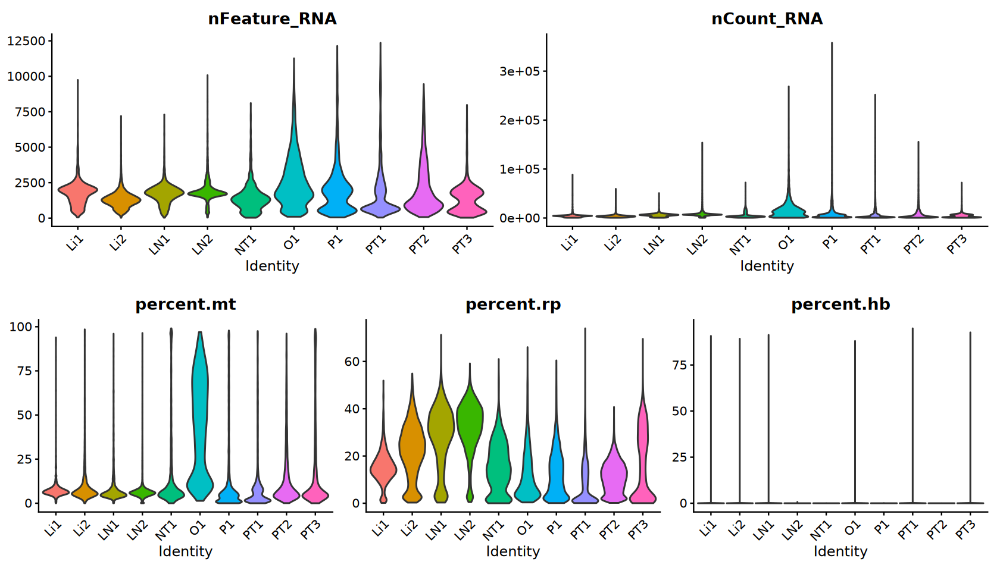

In [17]:
# Visualize QC metrics as a violin plot
p1 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("nFeature_RNA", "nCount_RNA"), 
    pt.size = 0, ncol = 2) & NoLegend()
p2 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("percent.mt", "percent.rp", "percent.hb"), 
    pt.size = 0, ncol = 3) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

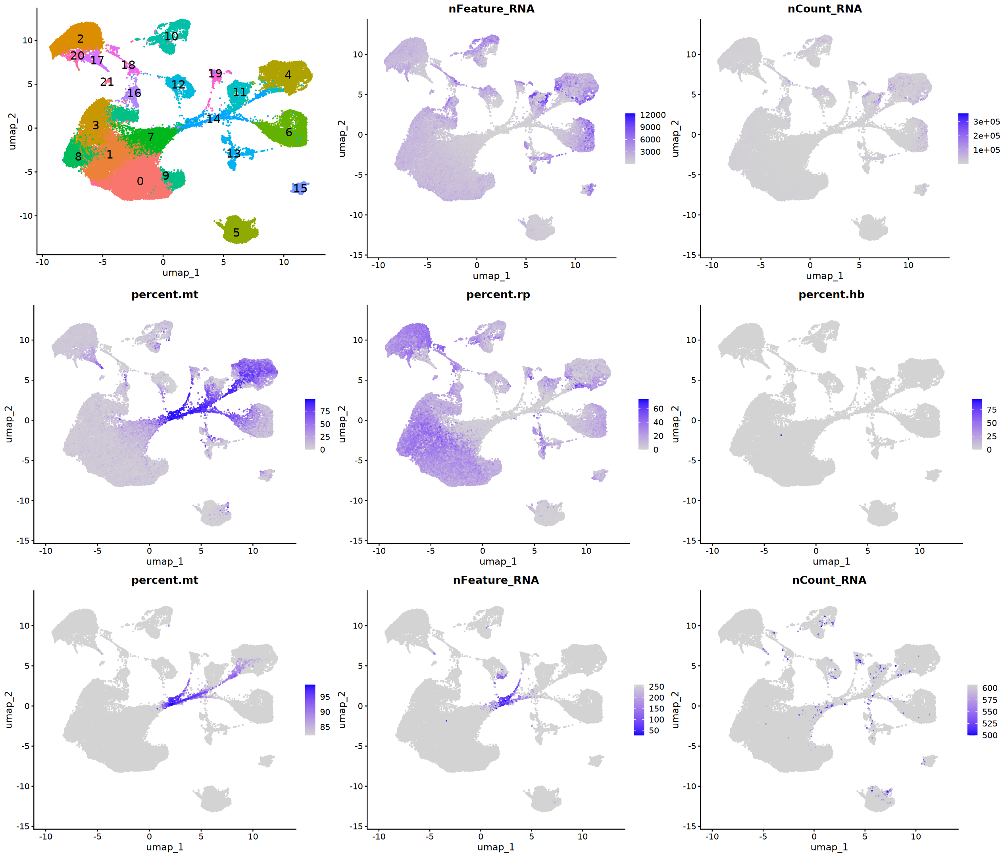

In [18]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE, combine = FALSE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q2", cols = c("blue", "lightgrey"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [19]:
source("R/calculate_mad_threshold.R")

In [20]:
cat(sprintf("Counts: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 2, sides = "lower")))

cat(sprintf("Features: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 2, sides = "lower")))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 2, sides = "upper")))

Counts: Lower: 740
Features: Lower: 491
Mitochondrial: Upper: 29


## 4). Filtering Low-quality Cells

In [21]:
scrna_list <- lapply(
    scrna_list, subset, 
    subset = nFeature_RNA > 500 & 
        percent.mt < 20)

scrna_list |> cell_stats() |> print()

  PT1   PT2   PT3   NT1   LN1   LN2    O1    P1   Li1   Li2 Total 
 2280  6382  2691  2140  3865  7500  1448  3892  1234 10061 41493 


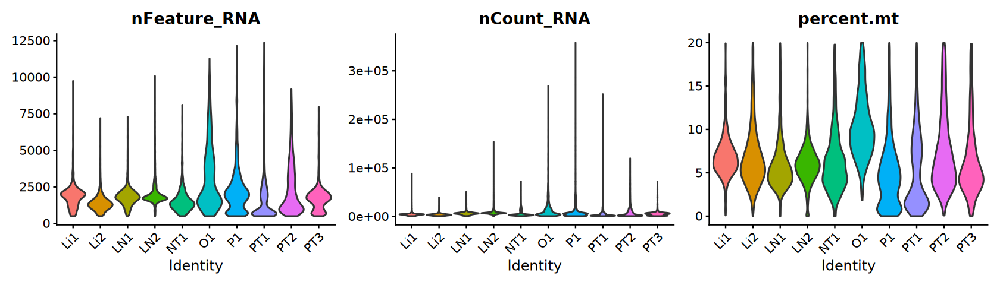

In [22]:
options(repr.plot.width = 14, repr.plot.height = 4)
merge(x = scrna_list[[1]], y = scrna_list[-1],
      add.cell.ids = names(scrna_list)) |>
    VlnPlot(layer = "counts", group.by = "orig.ident", 
            features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
            pt.size = 0, ncol = 3) & NoLegend()

## 5). Doublet Detection

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

In [23]:
source("R/run_DoubletFinder.R")

In [24]:
scrna_list <- lapply(
    scrna_list, run_DoubletFinder, ndim = 20, 
    clusters = "seurat_clusters", 
    multiplet.rate = 0.008, seed = 123)

[1] "Creating 760 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.27, nExp_adj = 31



[1] "Creating 2127 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.2, nExp_adj = 288



[1] "Creating 897 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.3, nExp_adj = 46



... (10 outputs left out)

[1] "Creating 411 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.24, nExp_adj = 10



[1] "Creating 3354 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.03, nExp_adj = 723



In [25]:
sapply(scrna_list, function(x) table(x$DoubletFinder.class))

,PT1,PT2,PT3,NT1,LN1,LN2,O1,P1,Li1,Li2
Singlet,2249,6094,2645,2110,3763,7122,1433,3790,1224,9338
Doublet,31,288,46,30,102,378,15,102,10,723


### b). [scDblFinder](https://github.com/plger/scDblFinder)

In [26]:
suppressPackageStartupMessages(library(scDblFinder))

In [27]:
run_scDblFinder <- function(
    obj, clusters = NULL, ndim = 10, seed = NULL) {
    
    if (!is.null(seed)) set.seed(seed)
    
    sce <- run_seurat_pipeline(obj, ndim = ndim) |>
        as.SingleCellExperiment()
    
    if (is.null(clusters)) {
        sce <- scDblFinder(sce, verbose = FALSE)
    } else {
        sce <- scDblFinder(
            sce, clusters = clusters, verbose = FALSE)
    }

    obj$scDblFinder.score <- colData(sce)$scDblFinder.score
    obj$scDblFinder.class <- colData(sce)$scDblFinder.class

    return(obj)
}

In [28]:
scrna_list <- lapply(
    scrna_list, run_scDblFinder, ndim = 20,
    clusters = "seurat_clusters", seed = 123)

In [29]:
sapply(scrna_list, function(x) table(x$scDblFinder.class))

,PT1,PT2,PT3,NT1,LN1,LN2,O1,P1,Li1,Li2
singlet,2189,5830,2550,2047,3649,6844,1390,3637,1189,8976
doublet,91,552,141,93,216,656,58,255,45,1085


### Filtering Doublets

In [30]:
sc.comb <- merge(
    x = scrna_list[[1]], y = scrna_list[-1],
    add.cell.ids = names(scrna_list), 
    project = "GastricCancer")
sc.comb

An object of class Seurat 
26093 features across 41493 samples within 1 assay 
Active assay: RNA (26093 features, 0 variable features)
 10 layers present: counts.PT1, counts.PT2, counts.PT3, counts.NT1, counts.LN1, counts.LN2, counts.O1, counts.P1, counts.Li1, counts.Li2

In [31]:
sc.comb$cancer <- case_when(
    grepl("NT\\d+", sc.comb$orig.ident) ~ "Normal",
    grepl("PT\\d+", sc.comb$orig.ident) ~ "Tumour",
    grepl("(LN|Li|O|P)\\d+", sc.comb$orig.ident) ~ "Metastasis",
    TRUE ~ as.character(sc.comb$orig.ident)
) |> factor(levels = c(
    "Normal", "Tumour", "Metastasis"))

table(sc.comb$cancer, useNA = "always")


    Normal     Tumour Metastasis       <NA> 
      2140      11353      28000          0 

In [32]:
sc.comb$tissue <- case_when(
    grepl("NT\\d+", sc.comb$orig.ident) ~ "Normal",
    grepl("PT\\d+", sc.comb$orig.ident) ~ "Stomach",
    grepl("Li\\d+", sc.comb$orig.ident) ~ "Liver",
    grepl("LN\\d+", sc.comb$orig.ident) ~ "LymphNodes",
    grepl("P\\d+", sc.comb$orig.ident) ~ "Peritoneal",
    grepl("O\\d+", sc.comb$orig.ident) ~ "Ovary",
    TRUE ~ as.character(sc.comb$orig.ident)
) |> factor(levels = c(
    "Normal", "Stomach", "Peritoneal", "LymphNodes", "Liver", "Ovary"))

table(sc.comb$tissue, useNA = "always")


    Normal    Stomach Peritoneal LymphNodes      Liver      Ovary       <NA> 
      2140      11353       3892      11365      11295       1448          0 

In [33]:
sc.comb$patient <- case_when(
    grepl("(PT1|Li1)", sc.comb$orig.ident) ~ "Patient1",
    grepl("(PT2|NT1)", sc.comb$orig.ident) ~ "Patient2",
    grepl("O1", sc.comb$orig.ident) ~ "Patient3",
    grepl("(PT3|Li2|LN1)", sc.comb$orig.ident) ~ "Patient4",
    grepl("LN2", sc.comb$orig.ident) ~ "Patient5",
    grepl("P1", sc.comb$orig.ident) ~ "Patient6",
    TRUE ~ as.character(sc.comb$orig.ident)
) |> factor(levels = c(
    "Patient1", "Patient2", "Patient3", 
    "Patient4", "Patient5", "Patient6"))

table(sc.comb$patient, useNA = "always")


Patient1 Patient2 Patient3 Patient4 Patient5 Patient6     <NA> 
    3514     8522     1448    16617     7500     3892        0 

In [34]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

In [35]:
sc.temp$scDblFinder.class <- sc.temp$scDblFinder.class |>
    factor(levels = c("singlet", "doublet"))
sc.temp$DoubletFinder.class <- sc.temp$DoubletFinder.class |>
    factor(levels = c("Singlet", "Doublet"))

In [36]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   37250    1051
    doublet    2518     674

In [37]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c(
        "scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")) |> 
    as.factor()

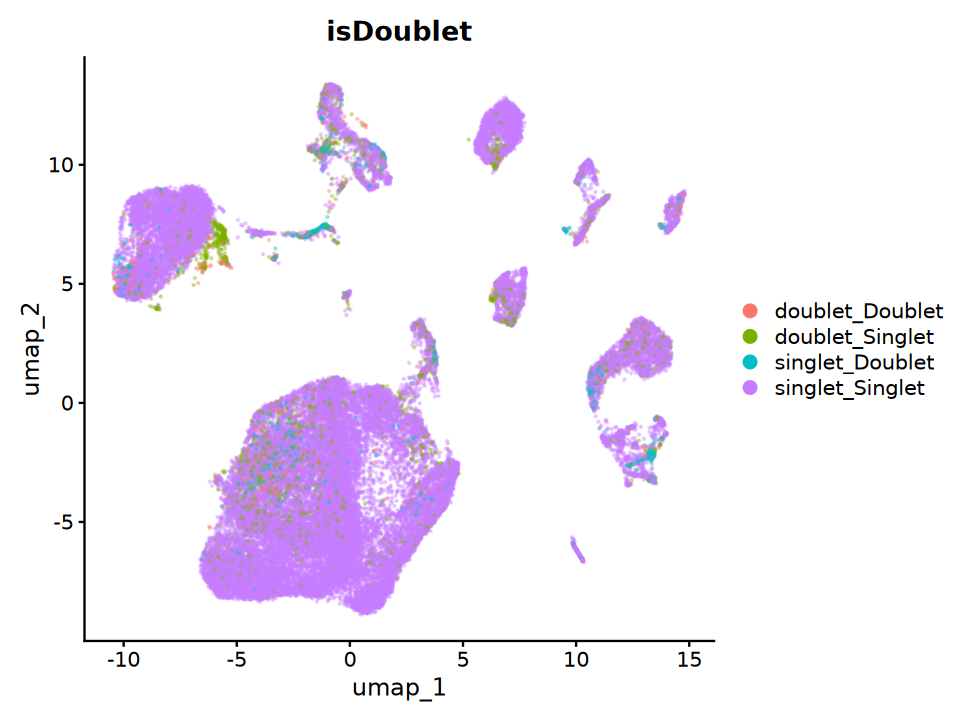

In [38]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap", 
        group.by = "isDoublet", 
        pt.size = 0.1, alpha = 0.3)

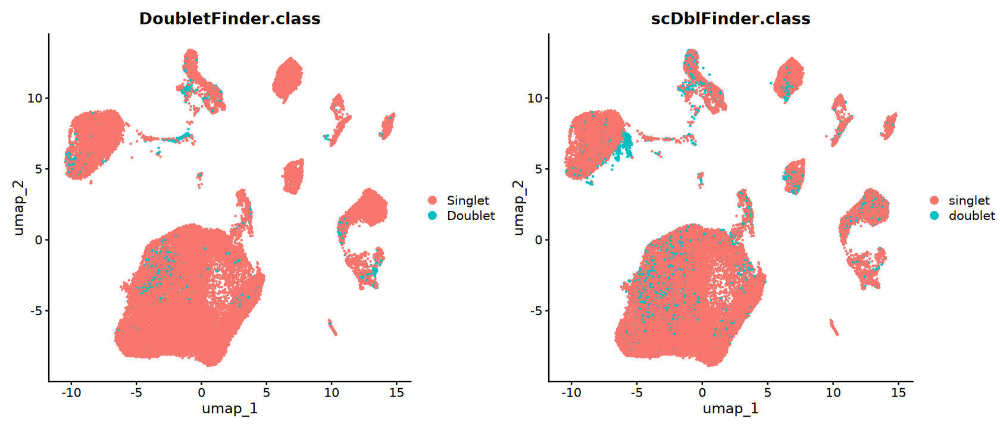

In [39]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [40]:
sc.temp <- subset(
    sc.temp,
    subset = scDblFinder.class == "singlet" | 
        DoubletFinder.class == "Singlet")
sc.temp

An object of class Seurat 
26093 features across 40819 samples within 1 assay 
Active assay: RNA (26093 features, 2000 variable features)
 21 layers present: counts.PT1, counts.PT2, counts.PT3, counts.NT1, counts.LN1, counts.LN2, counts.O1, counts.P1, counts.Li1, counts.Li2, data.PT1, data.PT2, data.PT3, data.NT1, data.LN1, data.LN2, data.O1, data.P1, data.Li1, data.Li2, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

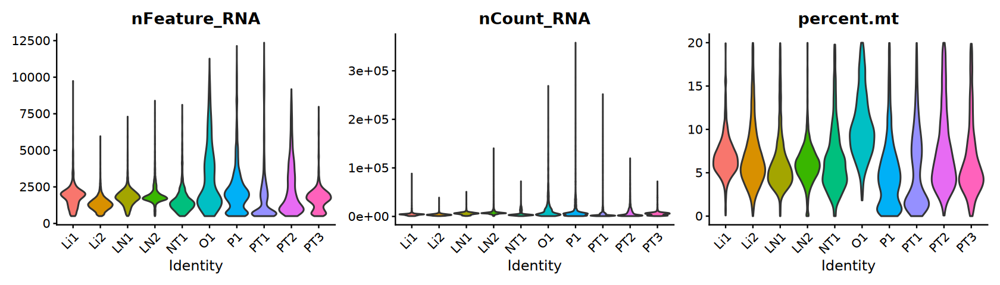

In [41]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

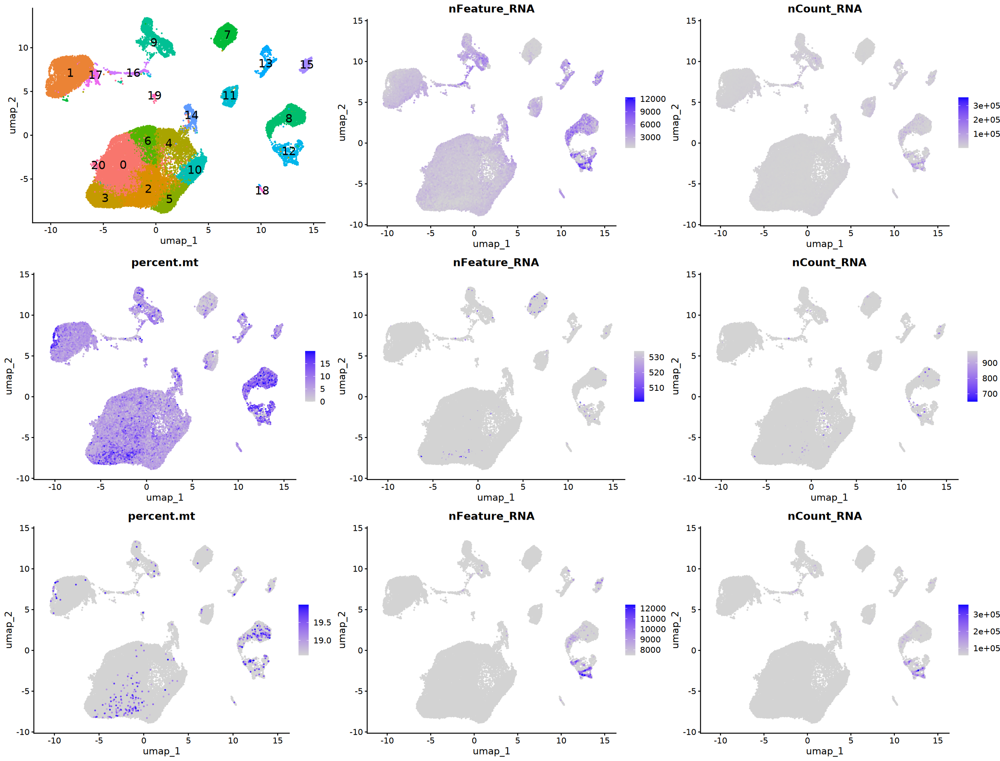

In [42]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p4 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 16)
plot_grid(
    plotlist = c(p1, p2, p3, p4), ncol = 3, byrow = TRUE
)

In [43]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA     nCount_RNA       percent.mt    
 Min.   :  501   Min.   :   649   Min.   : 0.000  
 1st Qu.: 1158   1st Qu.:  2746   1st Qu.: 4.125  
 Median : 1642   Median :  4916   Median : 5.865  
 Mean   : 1905   Mean   :  7475   Mean   : 6.545  
 3rd Qu.: 2124   3rd Qu.:  7509   3rd Qu.: 8.094  
 Max.   :12356   Max.   :357778   Max.   :19.994  

In [44]:
cat(sprintf("Counts: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 2, sides = "upper")))

cat(sprintf("Features: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 2, sides = "upper")))

Counts: Upper: 20827
Features: Upper: 3984


In [45]:
sc.comb <- sc.comb |> 
    subset(
        subset = scDblFinder.class == "singlet" | 
            DoubletFinder.class == "Singlet") |>
    subset(
        subset = nCount_RNA < 50000 & 
            percent.mt < 20 & percent.hb < 1)
sc.comb

An object of class Seurat 
26093 features across 40293 samples within 1 assay 
Active assay: RNA (26093 features, 0 variable features)
 10 layers present: counts.PT1, counts.PT2, counts.PT3, counts.NT1, counts.LN1, counts.LN2, counts.O1, counts.P1, counts.Li1, counts.Li2

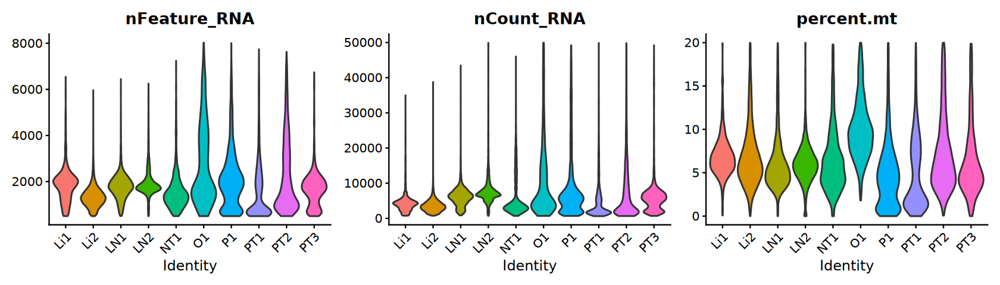

In [46]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.comb, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

## 6). Evaluating Noise

### a). Cell cycle effect

In [47]:
calculate_cell_cycle_score <- function(
    obj, species = c("human", "mouse")) {

    species <- match.arg(species)

    cc_s <- switch(
        species,
        "human" = cc.genes$s.genes,
        "mouse" = stringr::str_to_title(cc.genes$s.genes),
        tolower(cc.genes$s.genes))
    
    cc_g2m <- switch(
        species,
        "human" = cc.genes$g2m.genes,
        "mouse" = stringr::str_to_title(cc.genes$g2m.genes),
        tolower(cc.genes$g2m.genes))
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        CellCycleScoring(s.features = cc_s, g2m.features = cc_g2m, 
                         set.ident = FALSE)

    return(obj)
}

In [48]:
sc.comb <- calculate_cell_cycle_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in 

### b). Cell dissociation effect

In [49]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")

In [50]:
calculate_dissociation_score <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)

    diss_genes <- switch(
        species,
        "human" = toupper(dissociation_genes),
        "mouse" = dissociation_genes,
        tolower(dissociation_genes)
    )
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        AddModuleScore(name = "Dissociation.Score", 
                       features = list(dissociationGenes = diss_genes))
    obj@meta.data <- obj@meta.data |> 
        dplyr::rename("Dis.Score" = "Dissociation.Score1")
    
    return(obj)
}

In [51]:
sc.comb <- calculate_dissociation_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in th

### c). Batch effect

In [52]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

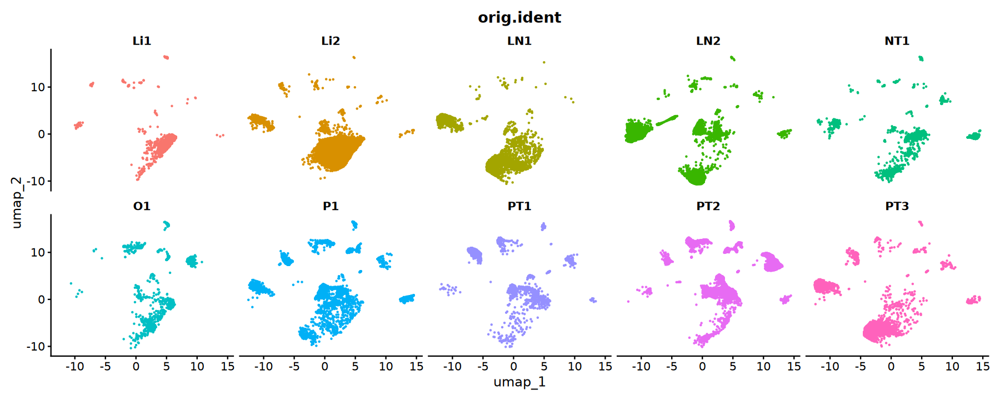

In [53]:
options(repr.plot.width = 15, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap", group.by = "orig.ident", 
        split.by = "orig.ident", ncol = 5) & NoLegend()

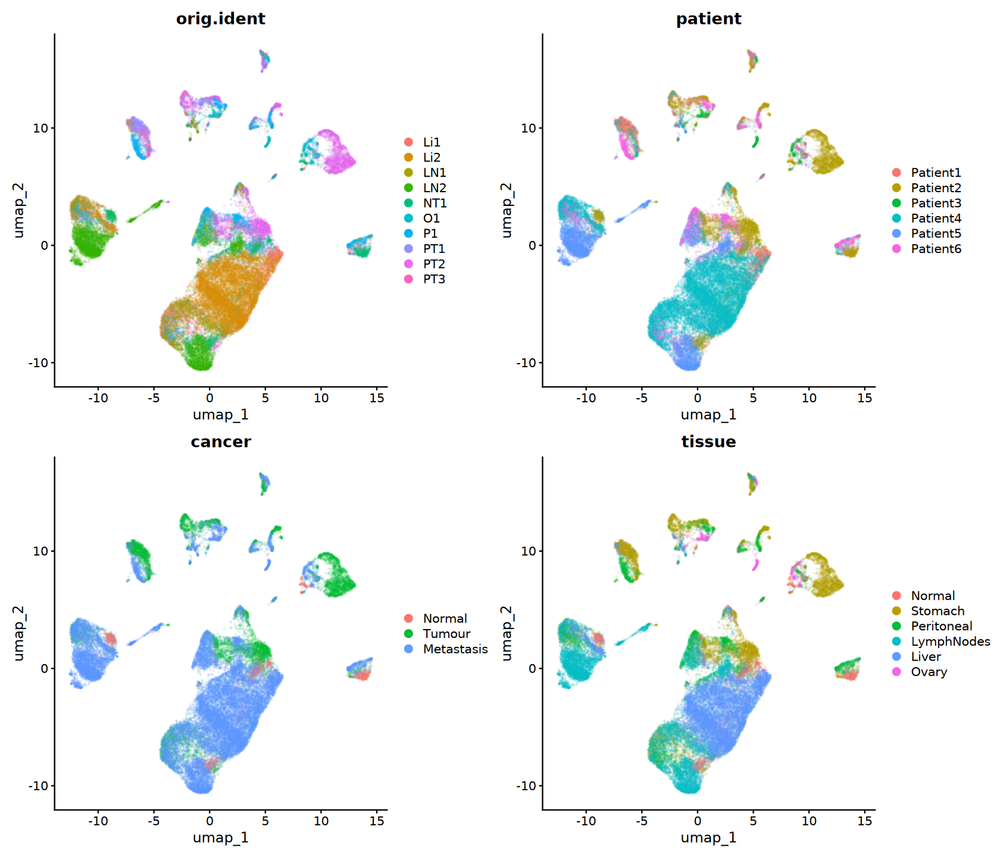

In [54]:
options(repr.plot.width = 14, repr.plot.height = 12)
DimPlot(sc.temp, reduction = "umap", 
        group.by = c("orig.ident", "patient", "cancer", "tissue"),
        pt.size = 0.1, alpha = 0.1, ncol = 2)

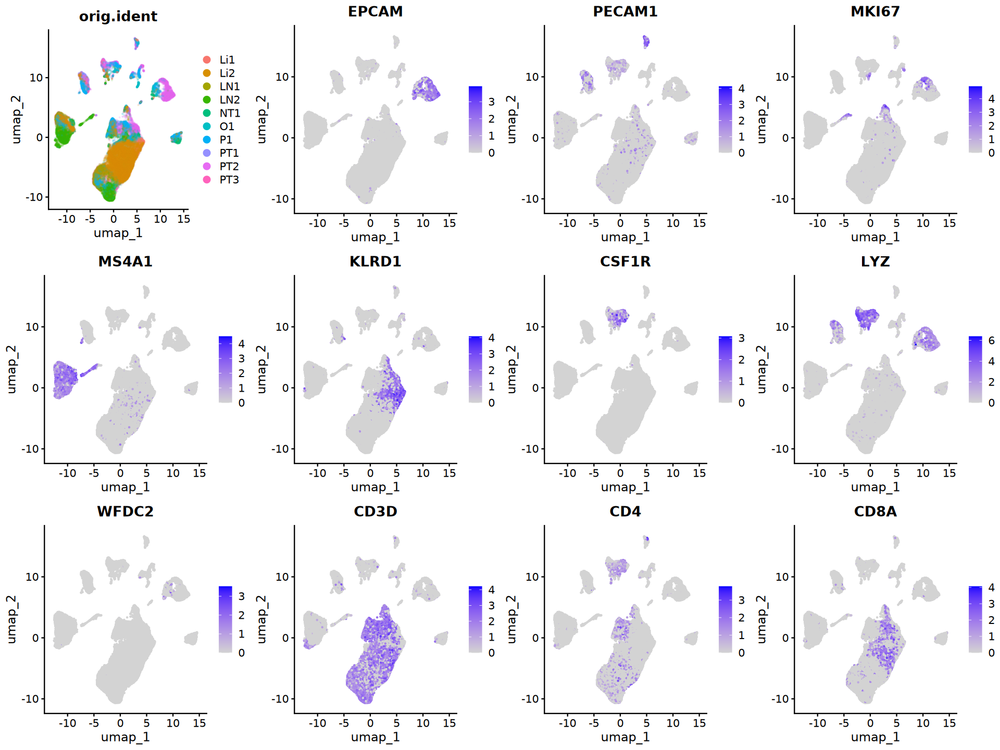

In [55]:
geneset <- c("EPCAM", "PECAM1", "MKI67", "MS4A1", "KLRD1", 
             "CSF1R", "LYZ", "WFDC2", "CD3D", "CD4", "CD8A")

p1 <- DimPlot(
    sc.temp, group.by = "orig.ident", reduction = "umap",
    pt.size = 0.1, alpha = 0.1, label = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 16, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 4)

# 3. Initial Assessment

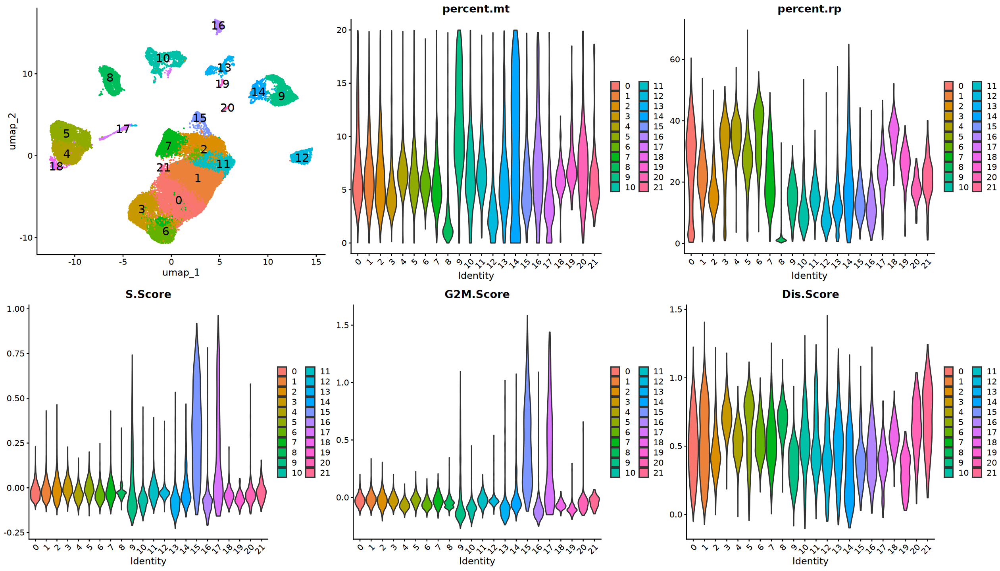

In [56]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

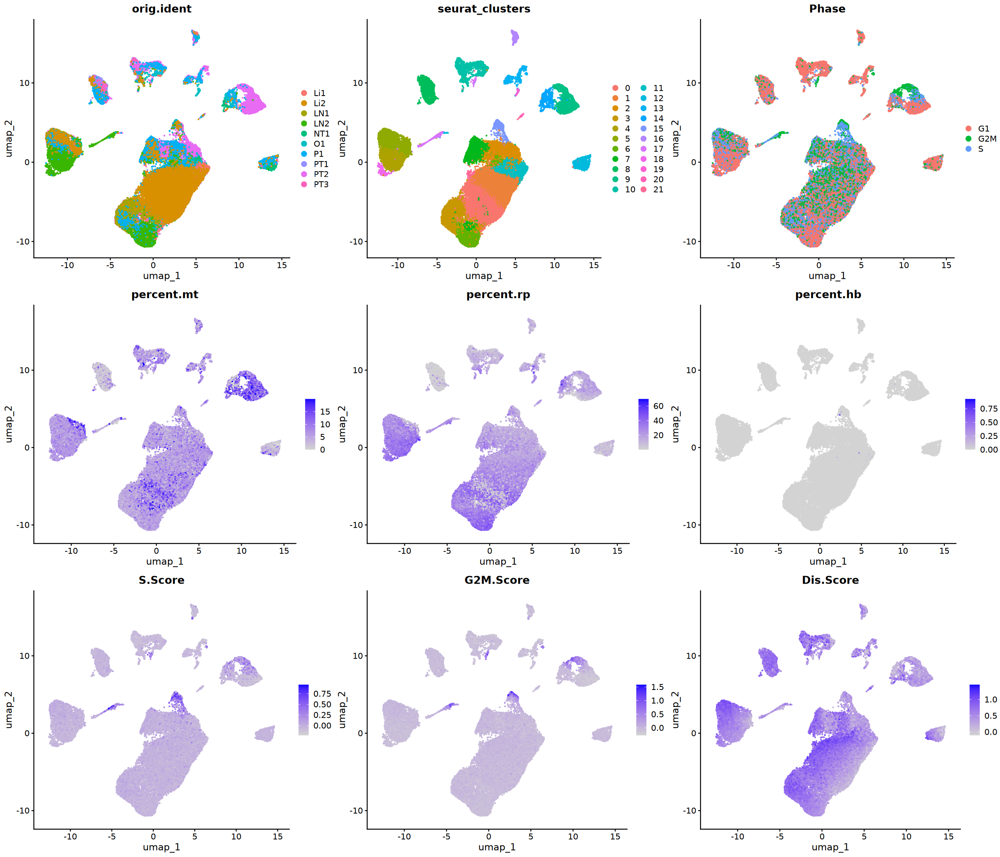

In [57]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

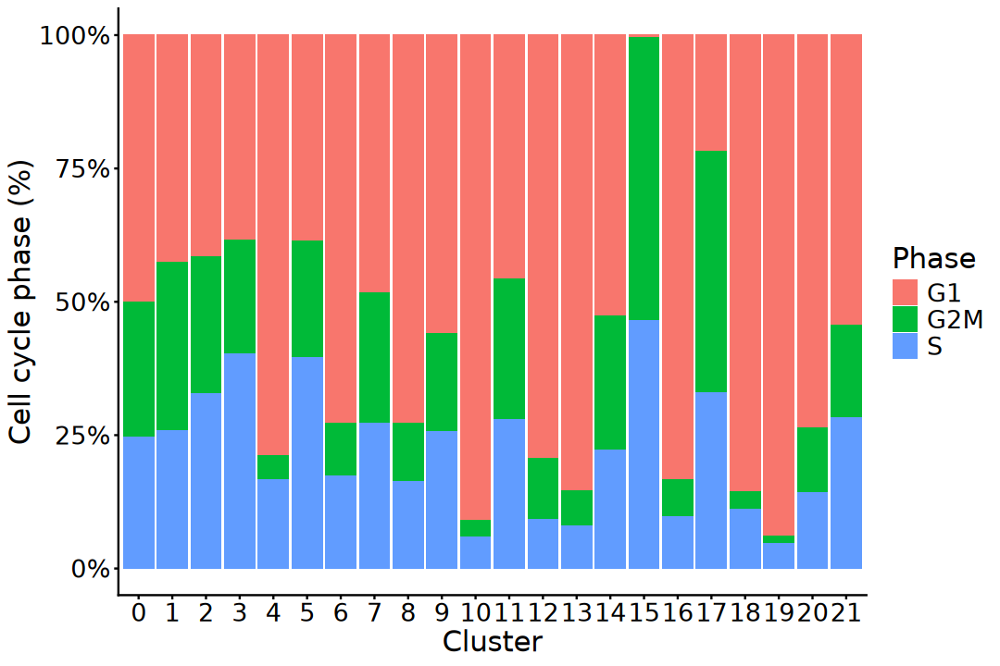

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [59]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

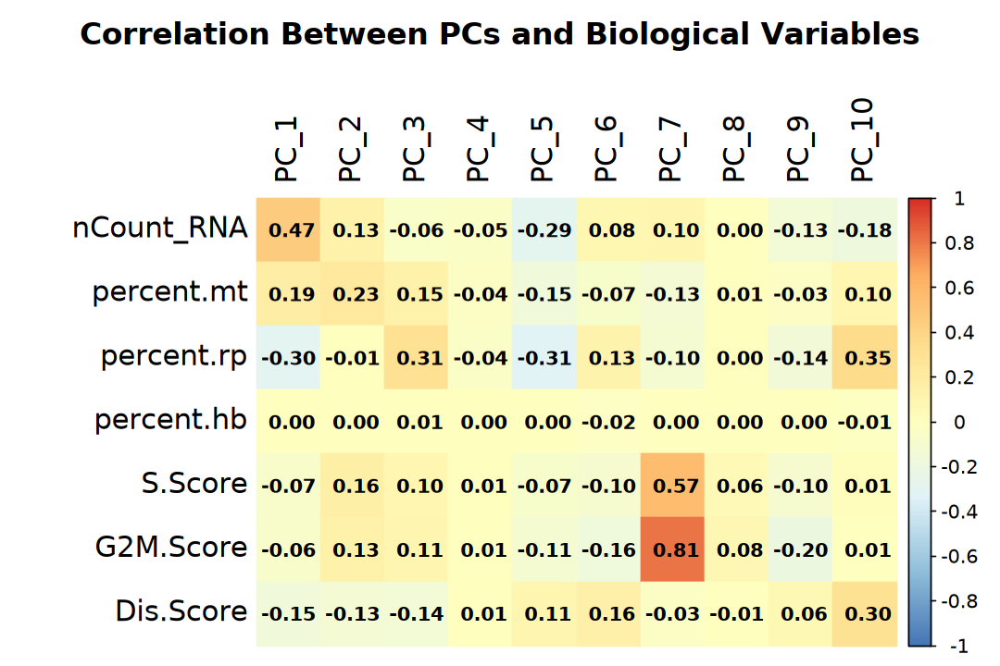

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-1, 1),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [61]:
sc.comb <- NormalizeData(sc.comb, verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 2000, verbose = FALSE) |>
    ScaleData(vars.to.regress = "percent.mt", verbose = FALSE)

# 5. Linear Dimensionality Reduction

In [62]:
sc.comb <- RunPCA(sc.comb, npcs = 50, verbose = FALSE)

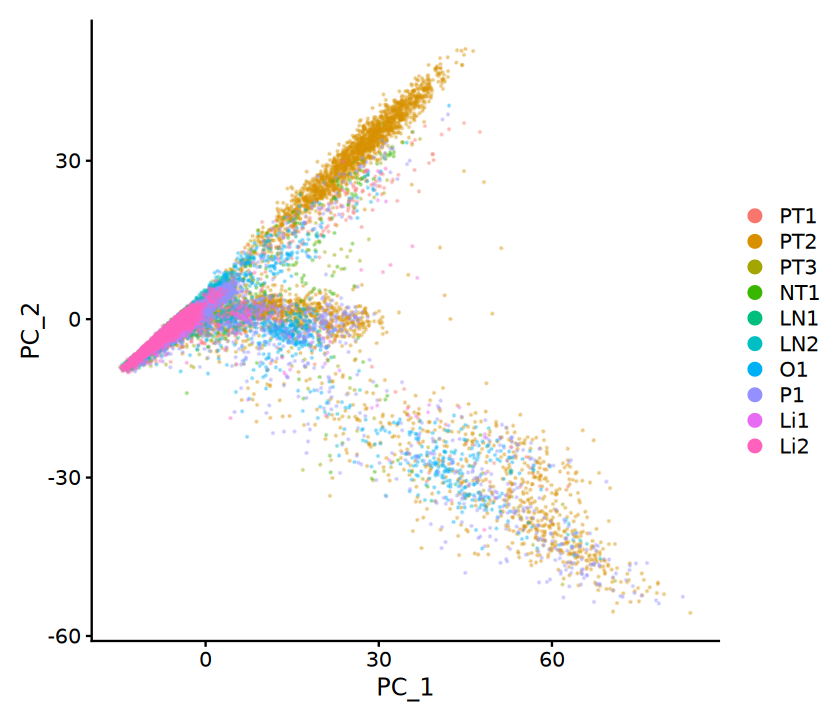

In [63]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "pca", alpha = 0.3)

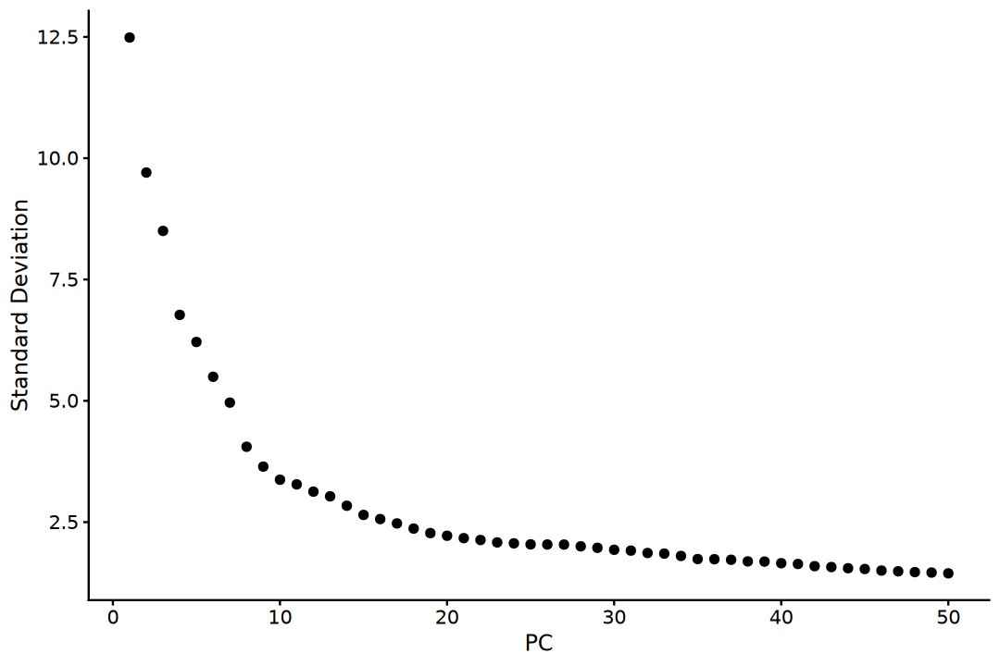

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(sc.comb, ndims = 50)

In [65]:
# Estimating PCA dimensionality
pca_var <- sc.comb@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 27


In [66]:
nPCs <- 30

# 6. Integration

In [67]:
sc.inte <- IntegrateLayers(
    sc.comb, method = CCAIntegration, orig.reduction = "pca", 
    new.reduction = "cca", verbose = FALSE)

In [68]:
inte <- "cca"

In [69]:
sc.inte <- JoinLayers(sc.inte)
sc.inte

An object of class Seurat 
26093 features across 40293 samples within 1 assay 
Active assay: RNA (26093 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 2 dimensional reductions calculated: pca, cca

# 7. Neighborhood Graph Construction

In [70]:
sc.inte <- FindNeighbors(
    sc.inte, k.param = 20, reduction = inte, 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [71]:
sc.inte <- RunUMAP(
    sc.inte, dims = seq_len(nPCs), reduction = inte, 
    verbose = FALSE)

In [72]:
sc.inte <- RunTSNE(
    sc.inte, dims = seq_len(nPCs), reduction = inte,
    verbose = FALSE)

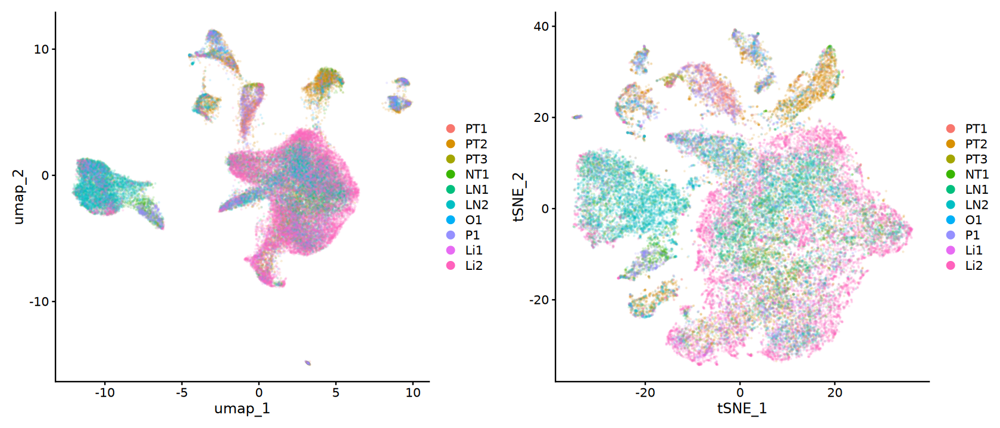

In [73]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", pt.size = 0.1, alpha = 0.1)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", pt.size = 0.1, alpha = 0.1)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [74]:
source("R/scan_clustering_resolution.R")

In [75]:
cluster_list <- scan_clustering_resolution(
    sc.inte, reduction = inte, dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1), assess = FALSE)

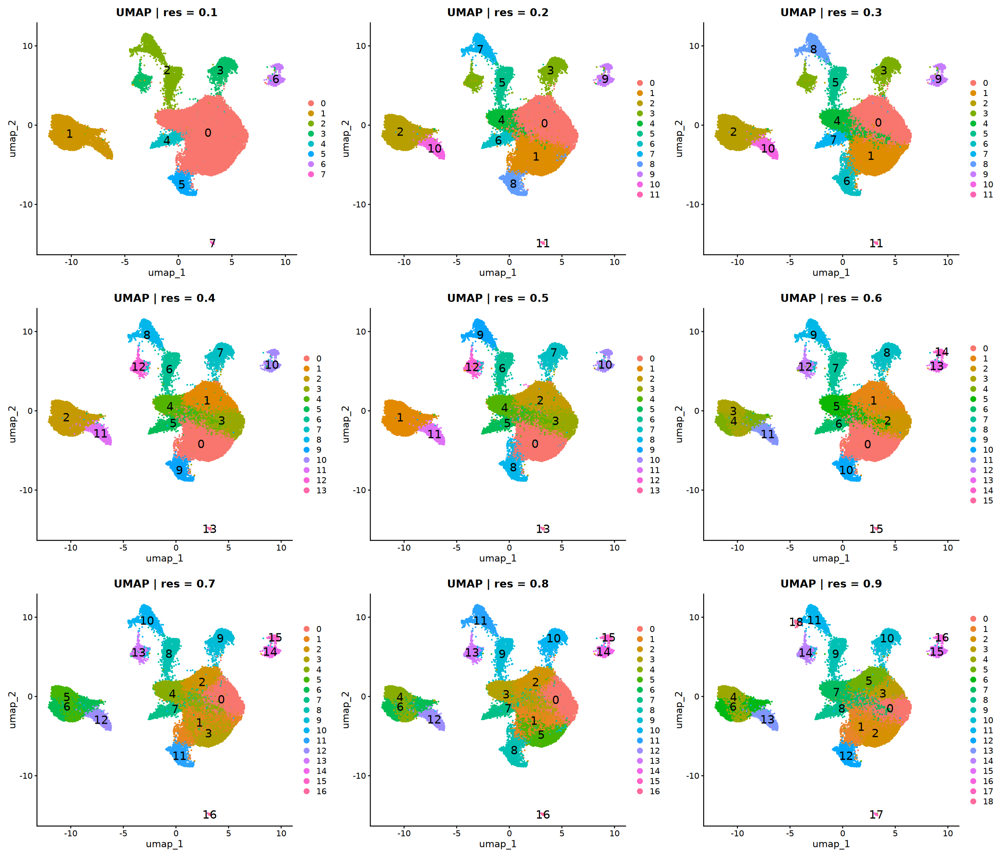

In [76]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

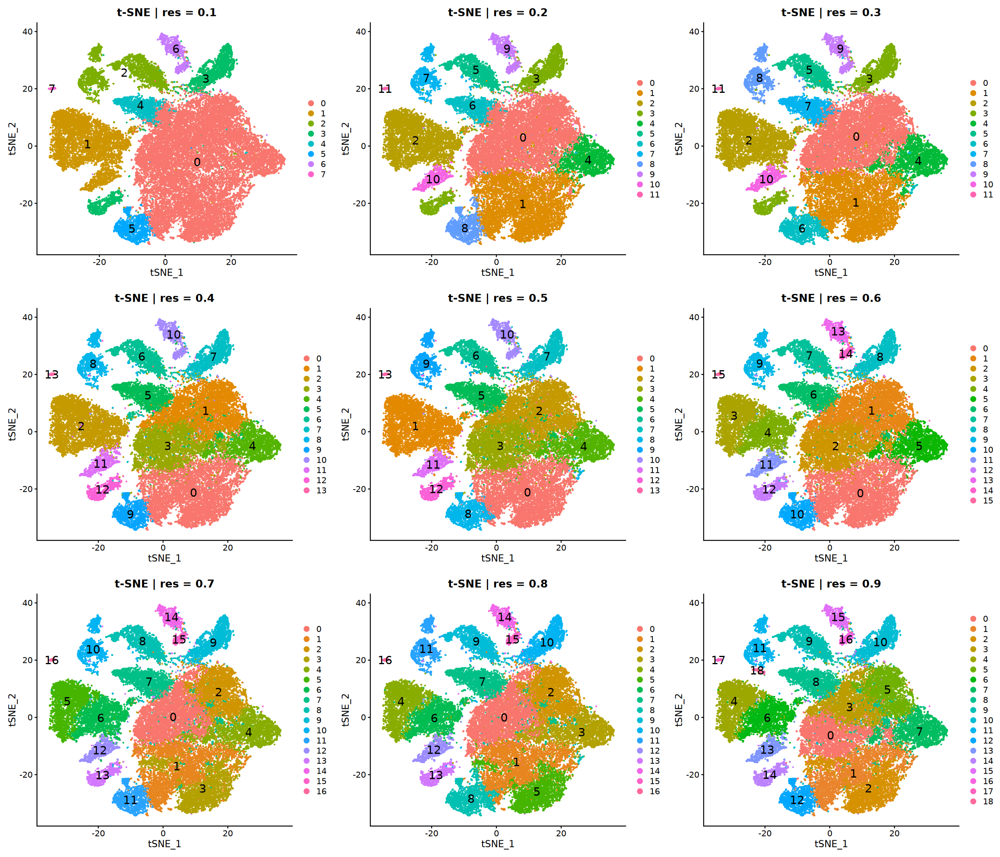

In [77]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$tsne, ncol = 3)

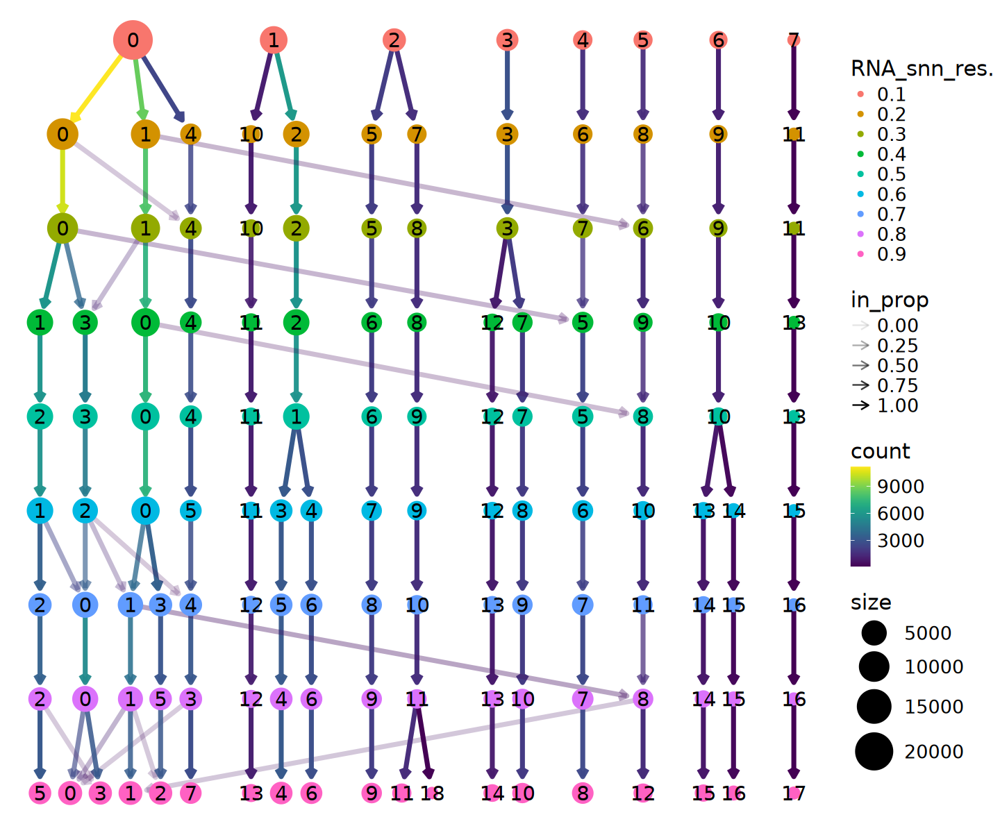

In [78]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [79]:
sc.inte <- FindClusters(
    sc.inte, resolution = 0.5, verbose = FALSE)

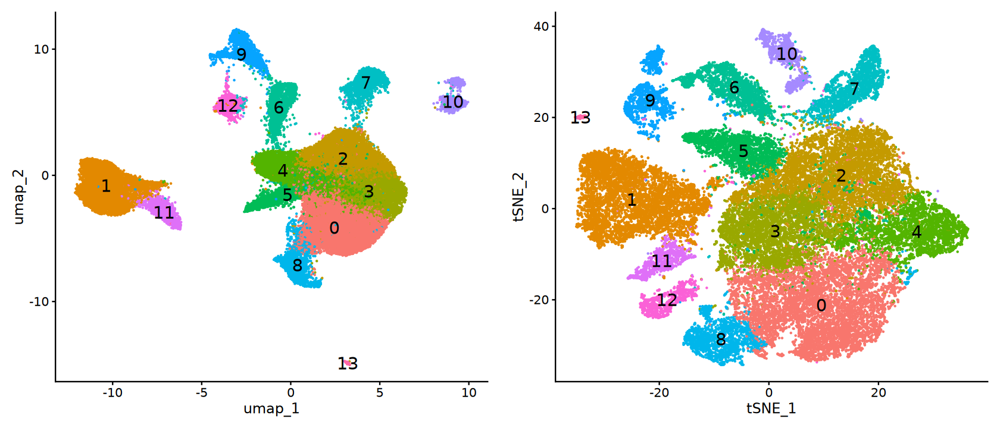

In [80]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6) & NoLegend()
p2 <- DimPlot(
    sc.inte, reduction = "tsne", label = TRUE,
    label.size = 6) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

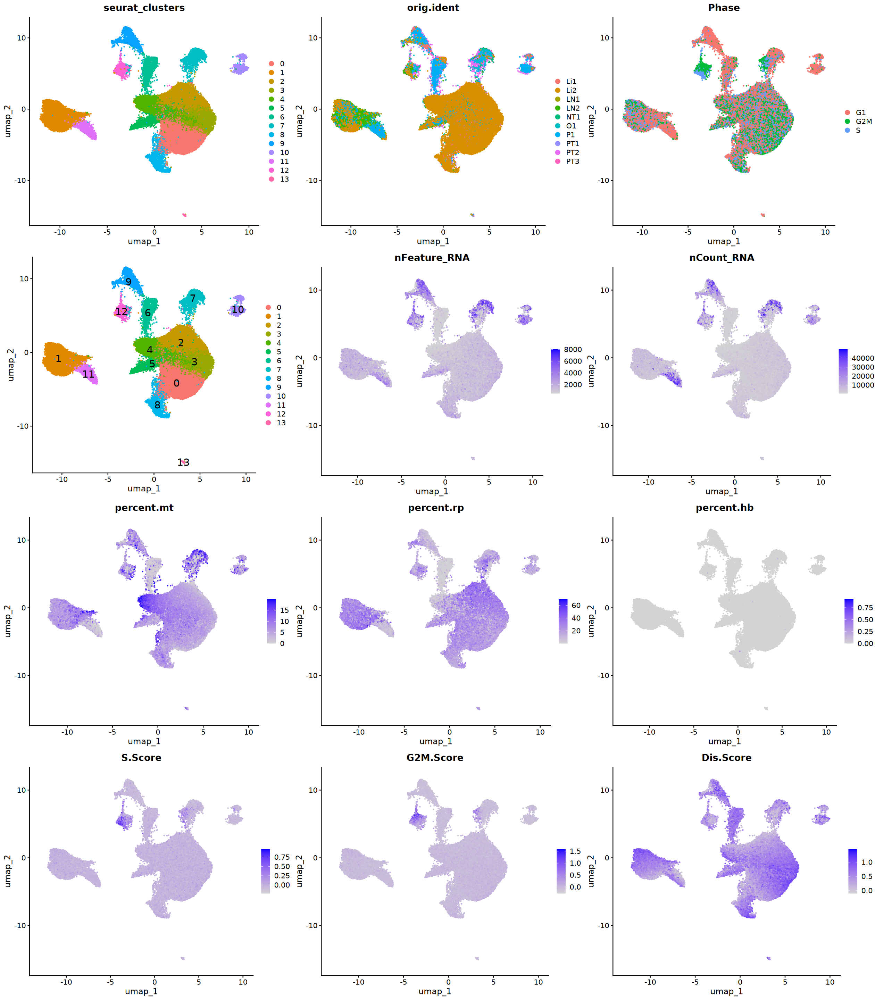

In [81]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6)
p3 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

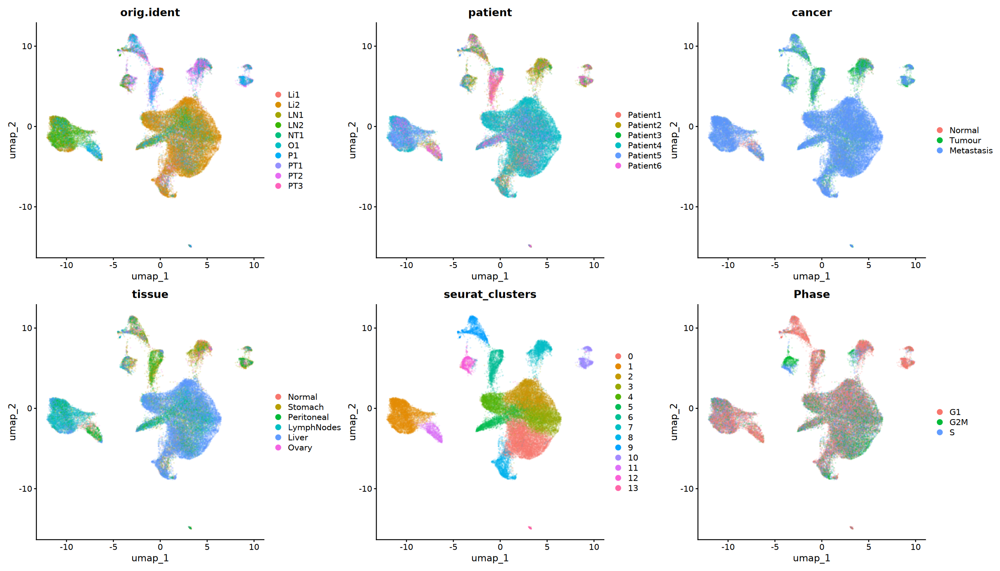

In [82]:
options(repr.plot.width = 21, repr.plot.height = 12)
DimPlot(sc.inte, reduction = "umap", combine = TRUE,
        group.by = c("orig.ident", "patient", "cancer", 
                     "tissue", "seurat_clusters", "Phase"),
        pt.size = 0.1, alpha = 0.1, ncol = 3)

# 10. Cluster Biomarkers

In [83]:
sc.markers <- FindAllMarkers(
    sc.inte, logfc.threshold = log2(1.2), min.pct = 0.25,
    only.pos = TRUE, verbose = FALSE)

In [84]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [85]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,5,6,7,8,9,10,11,12,13
length(gene),57,300,30,88,134,195,3347,93,1846,2885,397,2728,592


In [86]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

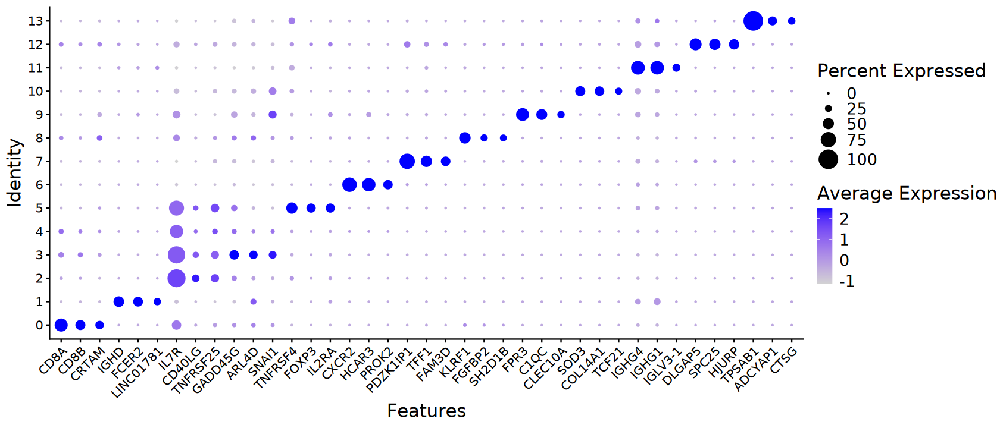

In [87]:
options(repr.plot.width = 14, repr.plot.height = 6)
DotPlot(sc.inte, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

# 11. Cell-type Annotation

## a). Automatic

In [88]:
suppressPackageStartupMessages(library(SingleR))
suppressPackageStartupMessages(library(celldex))

In [89]:
hpca <- HumanPrimaryCellAtlasData()
hpca

class: SummarizedExperiment 
dim: 19363 713 
metadata(0):
assays(1): logcounts
rownames(19363): A1BG A1BG-AS1 ... ZZEF1 ZZZ3
rowData names(0):
colnames(713): GSM112490 GSM112491 ... GSM92233 GSM92234
colData names(3): label.main label.fine label.ont

In [90]:
celltype.SingleR <- LayerData(sc.inte, assay = "RNA", layer = "data") |>
    SingleR(ref = hpca, labels = hpca$label.fine,
            clusters = sc.inte$seurat_clusters, 
            de.method = "classic")

In [91]:
sc.inte$celltype.SingleR <- 
    celltype.SingleR$labels[sc.inte$seurat_clusters]

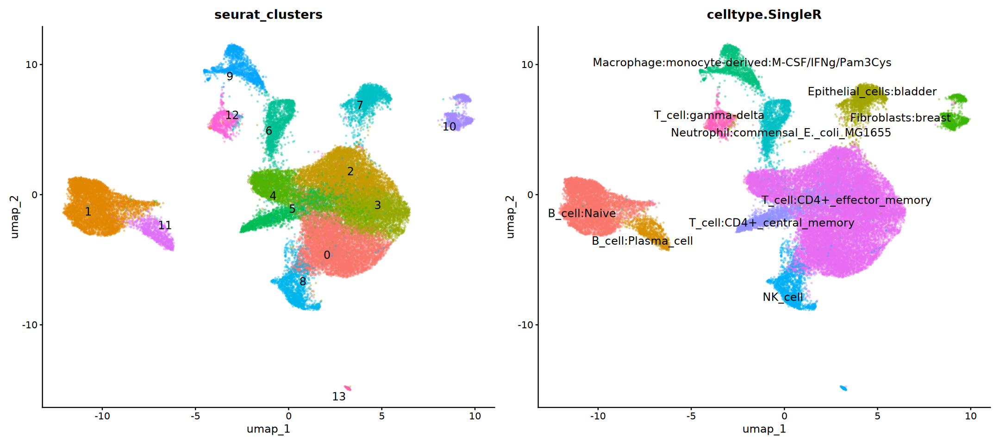

In [92]:
options(repr.plot.width = 18, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3,  ncol = 2) &
    NoLegend()

## b). Manual

In [93]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [94]:
gene_list |> cat(sep = "\n")

cluster_0: "CCL5", "CD8A", "GZMK", "CD8B", "GZMH", "TRGC2", "CRTAM", "IFNG", "DTHD1", "LAG3"
cluster_1: "BANK1", "VPREB3", "BLK", "IGHD", "CD19", "PAX5", "FCER2", "FCRL1", "LINC02397", "LINC01781"
cluster_2: "IL7R", "LTB", "GIMAP7", "SPOCK2", "ANXA1", "TRAT1", "CD40LG", "TNFRSF25", "CAMK4", "CD6"
cluster_3: "TCF7", "CITED2", "LEF1", "GADD45G", "PLK2", "C12orf65", "ARL4D", "SNAI1", "TRABD2A", "HSPA2"
cluster_5: "CTLA4", "BATF", "TNFRSF4", "TNFRSF18", "FOXP3", "IL2RA", "ICA1", "RTKN2", "LAIR2", "F5"
cluster_6: "FCGR3B", "CSF3R", "CXCR2", "HCAR3", "HCAR2", "CMTM2", "FFAR2", "PROK2", "S100A12", "CXCR1"
cluster_7: "FXYD3", "CLDN18", "PDZK1IP1", "SPINK1", "TFF3", "TFF1", "SLC6A14", "FAM3D", "LEMD1", "MUC5AC"
cluster_8: "KLRD1", "TRDC", "KLRF1", "GNLY", "CD160", "XCL1", "NCAM1", "KLRC2", "FGFBP2", "SH2D1B"
cluster_9: "CSF1R", "CD163", "FPR3", "MSR1", "MS4A4A", "C1QA", "C1QB", "C1QC", "VSIG4", "CLEC10A"
cluster_10: "SOD3", "COL14A1", "EDNRA", "SMOC2", "MFAP4", "PCDH18", "SFRP4", "ELN", "GUCY1A

> - Epithelial cells: "EPCAM", "KRT19", "CLDN4"
> - Stromal cells: "PECAM1", "COL1A2", "VWF"
> - Proliferative cells: "MKI67", "STMN1", "PCNA"
> - T cells: "CD3D", "CD3E", "CD2"
> - B cells: "CD79A", "IGHG1", "MS4A1"
> - Natural killer cells: "KLRD1", "GNLY", "KLRF1"
> - Myeloid cells: "CSF1R", "CSF3R", "CD68"

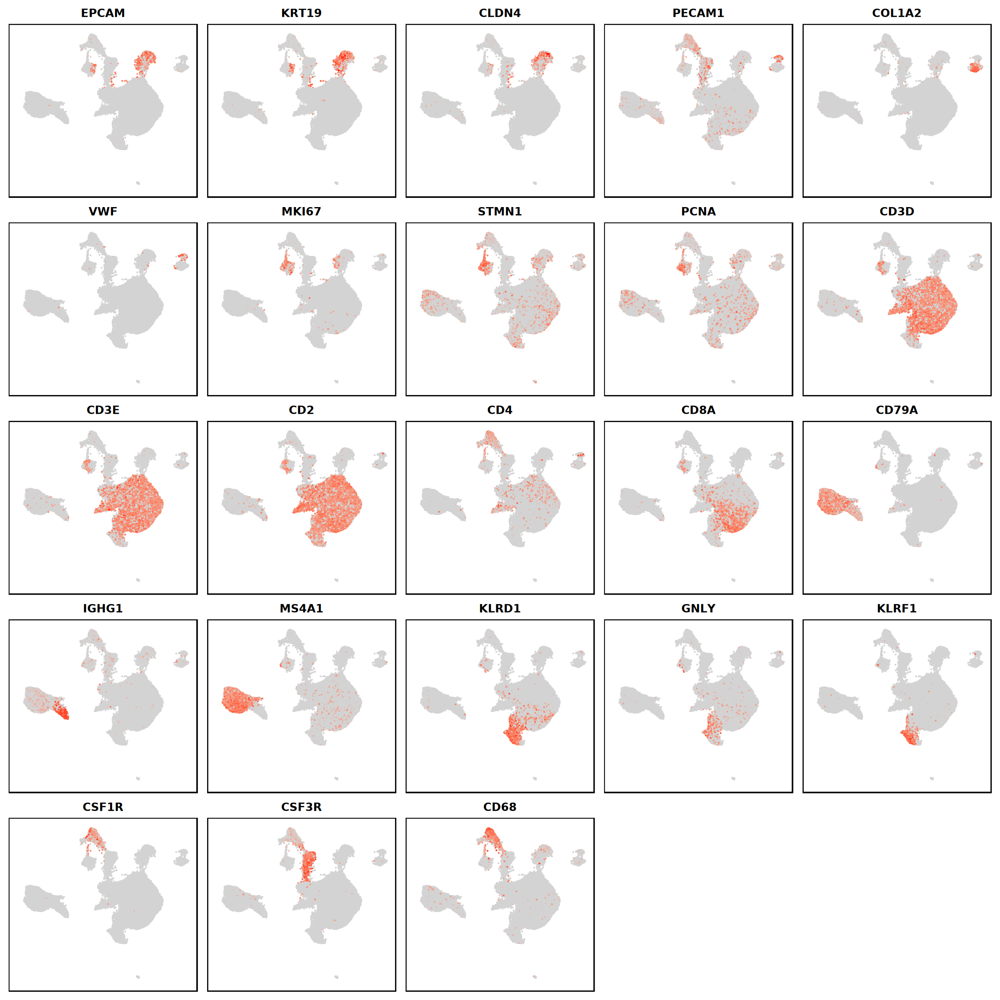

In [95]:
geneset <- c("EPCAM", "KRT19", "CLDN4", 
             "PECAM1", "COL1A2", "VWF",
             "MKI67", "STMN1", "PCNA",
             "CD3D", "CD3E", "CD2", "CD4", "CD8A",
             "CD79A", "IGHG1", "MS4A1",
             "KLRD1", "GNLY", "KLRF1", 
             "CSF1R", "CSF3R", "CD68")

options(repr.plot.width = 20, repr.plot.height = 20)
FeaturePlot(sc.inte, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

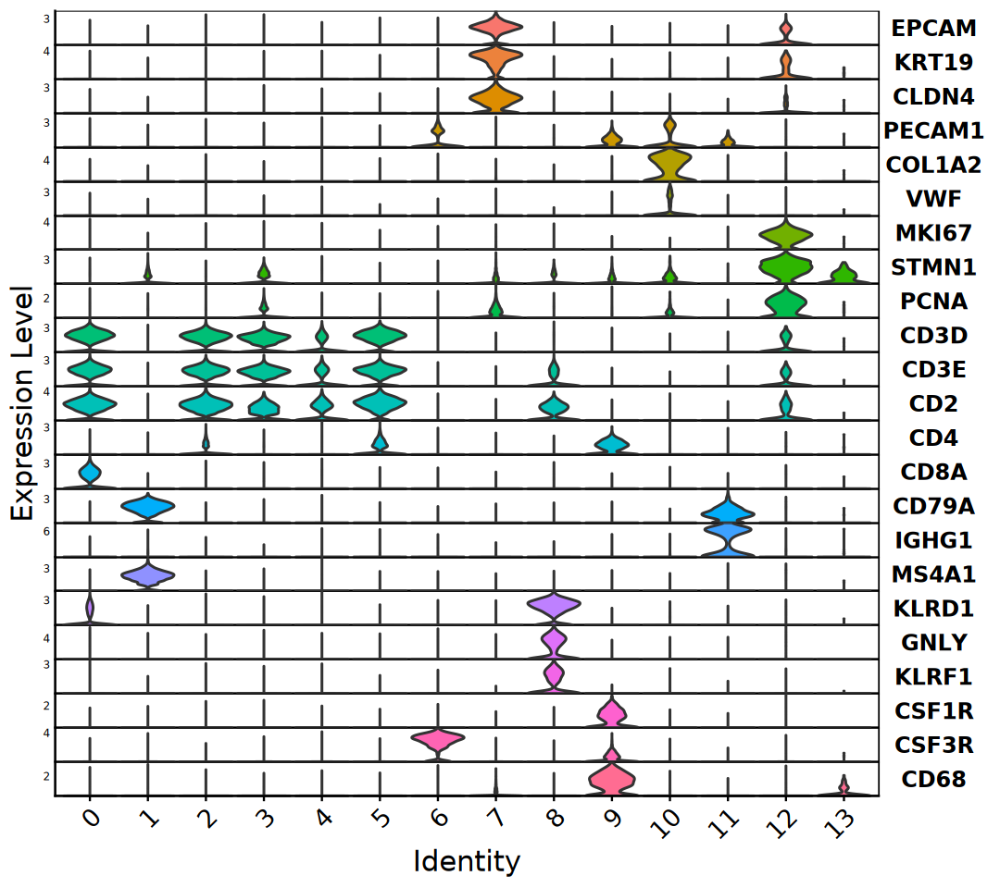

In [96]:
options(repr.plot.width = 9, repr.plot.height = 8)
VlnPlot(sc.inte, features = geneset, 
        stack = TRUE, flip = TRUE) +
    theme(legend.position = "none", 
          strip.text = element_text(size = 14),
          axis.ticks.y = element_blank(),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16))

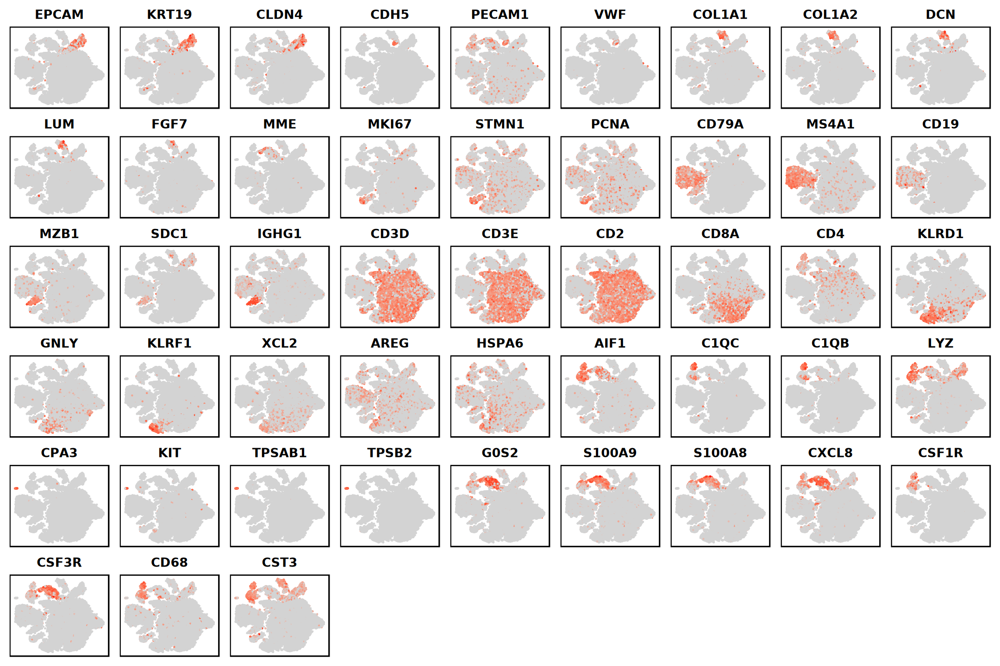

In [97]:
refMarkerGenes <- c(
    "EPCAM", "KRT19", "CLDN4",  # Epithelial cell
    "CDH5", "PECAM1", "VWF",  # Endothelial cell
    "COL1A1", "COL1A2", "DCN", "LUM",  # Stromal cell
    "LUM", "FGF7", "MME",  # Fibroblast cell
    "MKI67", "STMN1", "PCNA",  # Proliferative cell
    "CD79A", "MS4A1", "CD19", "MZB1", "SDC1", "IGHG1",  # B cell
    "CD3D", "CD3E", "CD2", "CD8A", "CD4", # T cell
    "KLRD1", "GNLY", "KLRF1", "XCL2", "AREG", "HSPA6", # NK cell
    "AIF1", "C1QC", "C1QB", "LYZ",  # Macrophage
    "CPA3", "KIT", "TPSAB1", "TPSB2", # Mast cell
    "G0S2", "S100A9", "S100A8", "CXCL8", # Neutrophil
    "CSF1R", "CSF3R", "CD68", "CST3" # Myeloid cell
)

options(repr.plot.width = 18, repr.plot.height = 12)
FeaturePlot(sc.inte, features = refMarkerGenes, cols = c("lightgrey", 'red'),
            reduction = "tsne", ncol = 9) & NoLegend() & NoAxes() + 
    theme(panel.border = element_rect(color = "black", linewidth = 1))

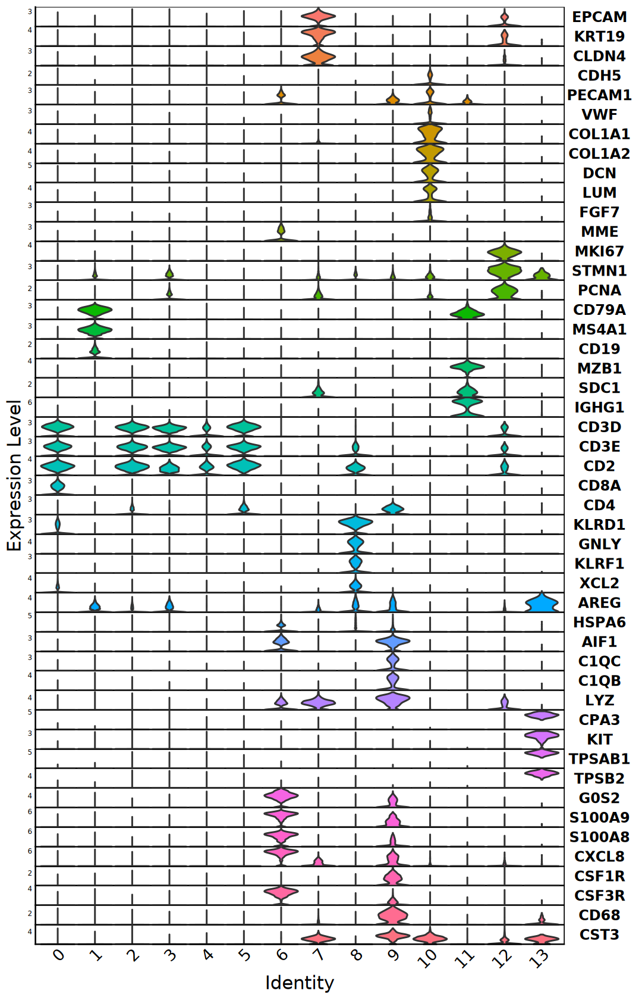

In [98]:
options(repr.plot.width = 9, repr.plot.height = 14)
VlnPlot(sc.inte, features = refMarkerGenes, 
        stack = TRUE, flip = TRUE) +
    theme(legend.position = "none", 
          strip.text = element_text(size = 14),
          axis.ticks = element_blank(),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16))

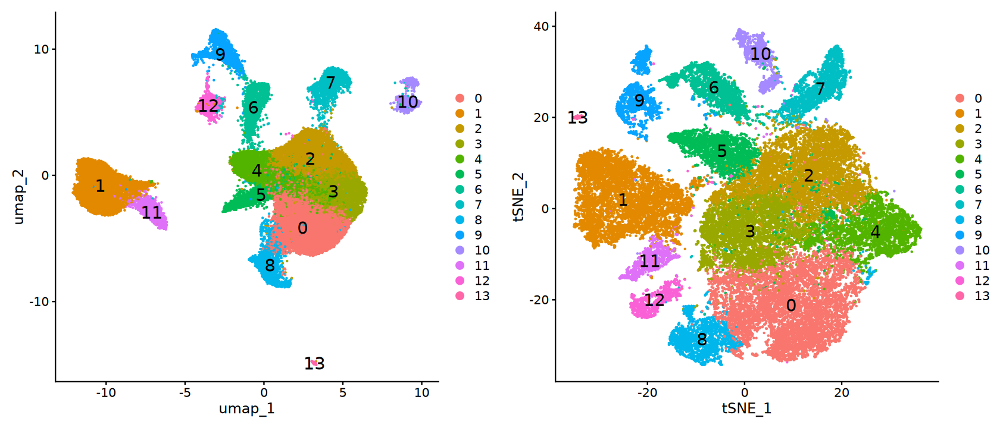

In [99]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [100]:
# Cell annotation with ChatGPT assistance
group2celltype <- c(
    "0" = "T", "1" = "B", "2" = "T",
    "3" = "T", "4" = "T", "5" = "T", 
    "6" = "Myeloid", "7" = "Epithelial", "8" = "NK",
    "9" = "Myeloid", "10" = "Stromal", "11" = "B",
    "12" = "Proliferative", "13" = "Myeloid")

In [101]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "CD8 T", "1" = "B", "2" = "CD4 T",
    "3" = "T", "4" = "T", "5" = "CD4 T", 
    "6" = "Neutrophil", "7" = "Epithelial", "8" = "NK",
    "9" = "Macrophage", "10" = "Stromal", "11" = "Plasmablast",
    "12" = "Proliferative", "13" = "Mast cell")

In [102]:
sc.inte@meta.data$celltype <- 
    cluster2celltype[as.character(sc.inte$seurat_clusters)]
sc.inte@meta.data$grouptype <- 
    group2celltype[as.character(sc.inte$seurat_clusters)]

sc.inte <- RenameIdents(sc.inte, cluster2celltype)

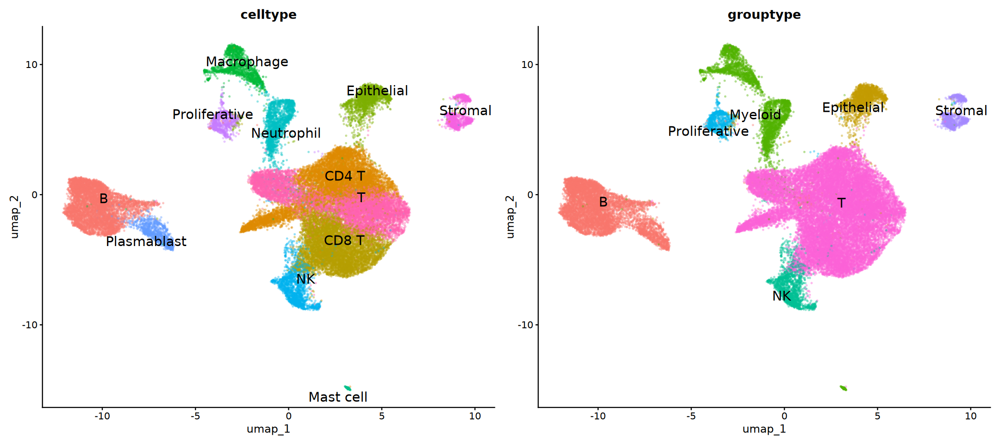

In [103]:
options(repr.plot.width = 18, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "umap",
        group.by = c("celltype", "grouptype"), 
        label = TRUE, repel = TRUE, label.size = 6, 
        pt.size = 0.3,  alpha = 0.3) & 
    NoLegend()

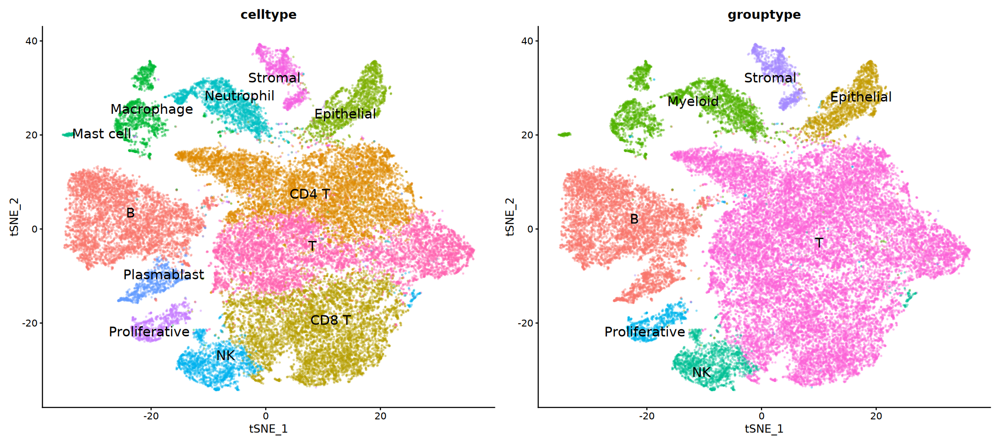

In [104]:
options(repr.plot.width = 18, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "tsne",
        group.by = c("celltype", "grouptype"), 
        label = TRUE, repel = TRUE, label.size = 6, 
        pt.size = 0.3,  alpha = 0.3) & 
    NoLegend()

In [105]:
qs2::qs_save(sc.inte, file.path(
    data_dir, "result", "s11_annotation_seurat_V5.qs2"))

## Visualization

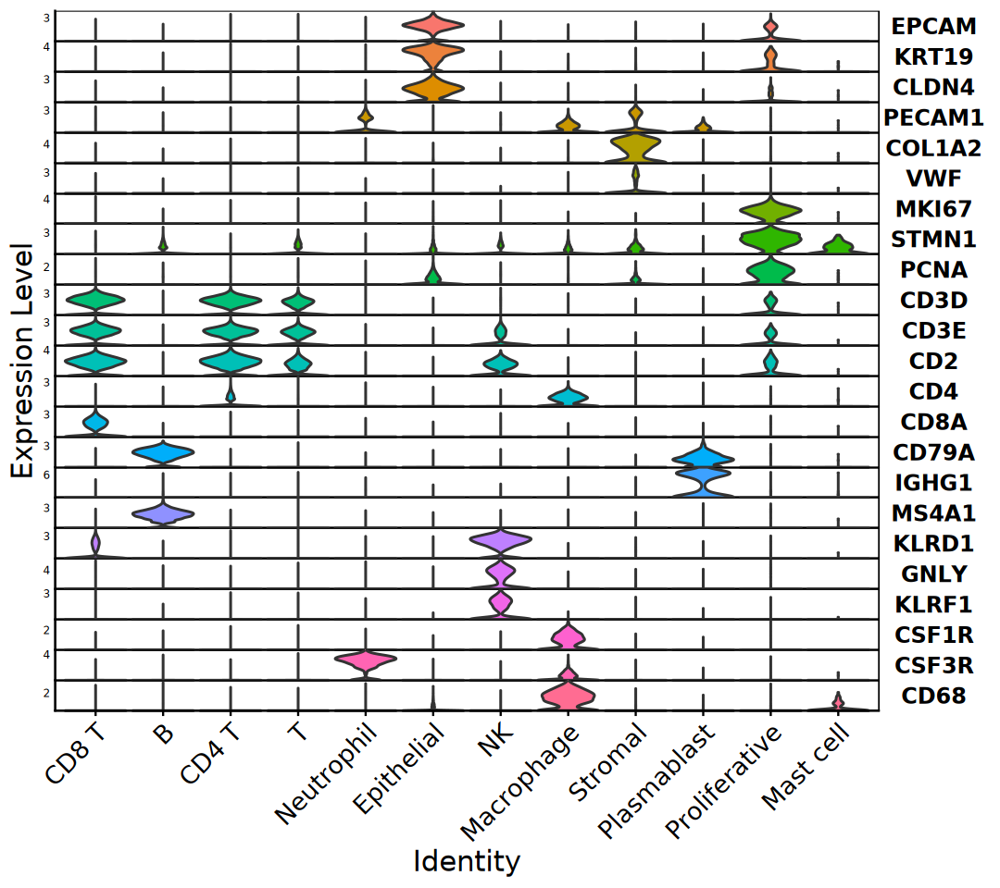

In [106]:
options(repr.plot.width = 9, repr.plot.height = 8)
VlnPlot(sc.inte, features = geneset, 
        stack = TRUE, flip = TRUE) +
    theme(legend.position = "none", 
          strip.text = element_text(size = 14),
          axis.ticks.y = element_blank(),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16))

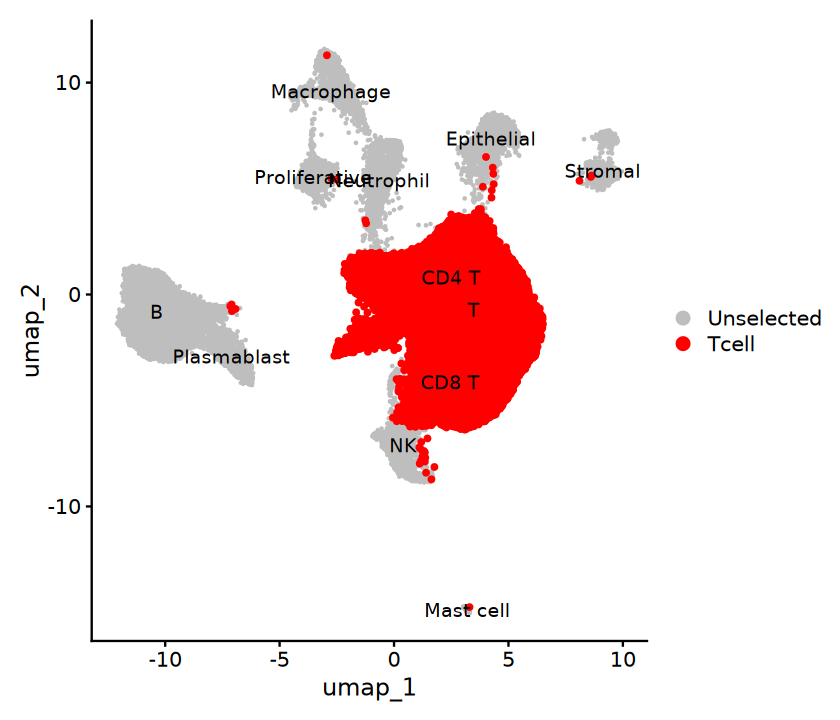

In [107]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.inte, reduction = "umap", label = TRUE, pt.size = 0.1,
        cells.highlight = list(
            Tcell = WhichCells(
                sc.inte, idents = c("T", "CD8 T", "CD4 T"))),
        cols.highlight = c("red"), cols = "grey")

In [108]:
# options(repr.plot.width = 21, repr.plot.height = 6)
# Plot_Density_Joint_Only(sc.inte, features = c("CD4", "CCR7"))

In [109]:
suppressPackageStartupMessages(library(ggnewscale))

In [110]:
plot_df <- as.data.frame(sc.inte@reductions$tsne@cell.embeddings)
plot_df$cluster <- factor(sc.inte$celltype)

In [111]:
expr_df <- as.data.frame(
    LayerData(sc.inte, assay = "RNA", layer = "data")[
        c('CD4','CD8A','CD8B'), ])

In [112]:
merged_df <- merge(t(expr_df), plot_df, by = 0, all = TRUE)

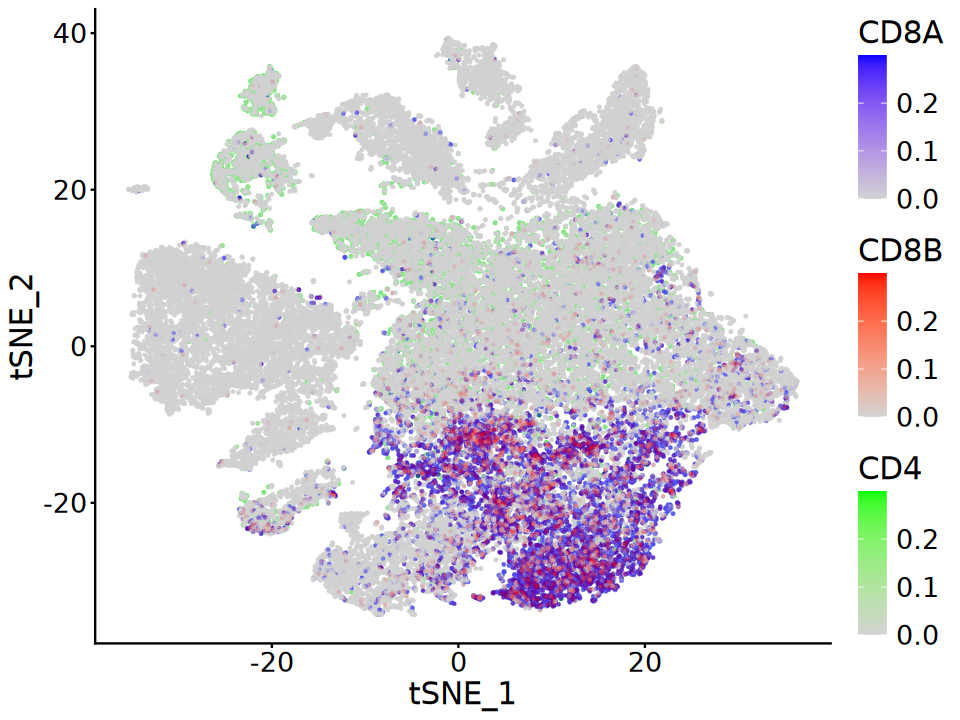

In [113]:
options(repr.plot.width = 8, repr.plot.height = 6)
ggplot(merged_df, aes(x = tSNE_1, y = tSNE_2, colour = CD4)) +
    geom_point(size = 0.3, alpha = 1) +
    scale_colour_gradientn(
        colours = c("lightgrey", "green"), limits = c(0, 0.3), 
        oob = scales::squish) +
    new_scale_color() +
    geom_point(aes(colour = CD8A), size = 0.3, alpha = 0.5) +
    scale_colour_gradientn(
        colours = c("lightgrey", "blue"), limits = c(0, 0.3), 
        oob = scales::squish) +
    new_scale_color() +
    geom_point(aes(colour = CD8B), size = 0.3, alpha = 0.1) +
    scale_colour_gradientn(
        colours = c("lightgrey", "red"), limits = c(0, 0.3), 
        oob = scales::squish)+
    theme_classic() +
    theme(legend.title = element_text(size = 18),
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16))

Warning message in DoHeatmap(subset(sc.inte, downsample = 100), refMarkerGenes, :
“The following features were omitted as they were not found in the scale.data layer for the RNA assay: CD4, CD2, CD3E, CD3D, CD19”
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


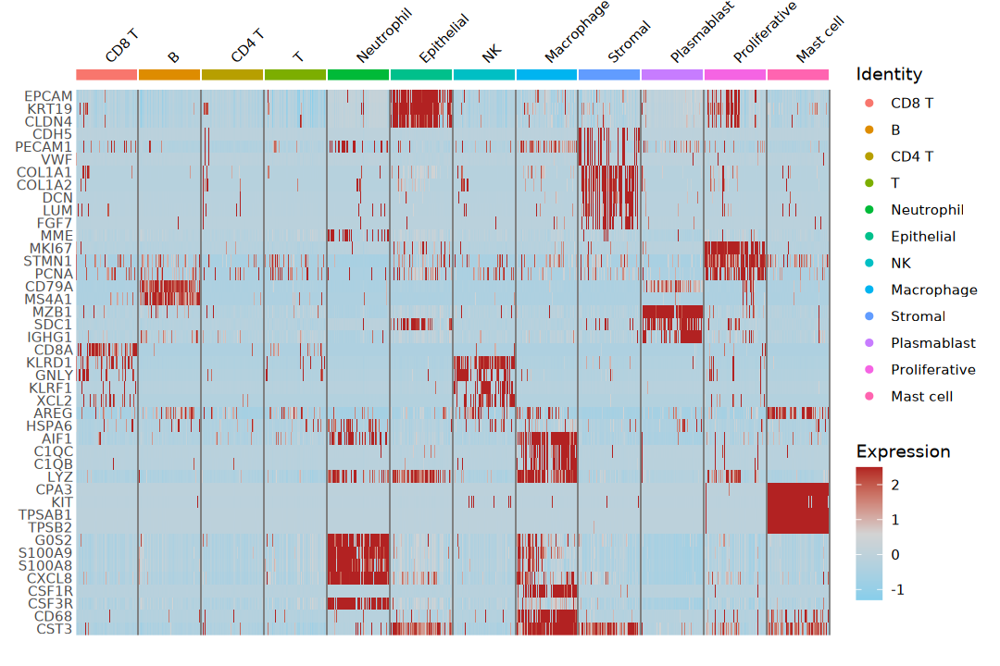

In [114]:
options(repr.plot.width = 9, repr.plot.height = 6)
DoHeatmap(subset(sc.inte, downsample = 100), refMarkerGenes, size = 3) +
    scale_fill_gradientn(colors = c("SkyBlue", "LightGray", "FireBrick"))

# 12. Cell Composition

In [115]:
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(ggforce))
suppressPackageStartupMessages(library(RColorBrewer))

In [116]:
cc_df <- sc.inte@meta.data |> 
    select(orig.ident, patient, cancer, tissue,
           celltype, grouptype)

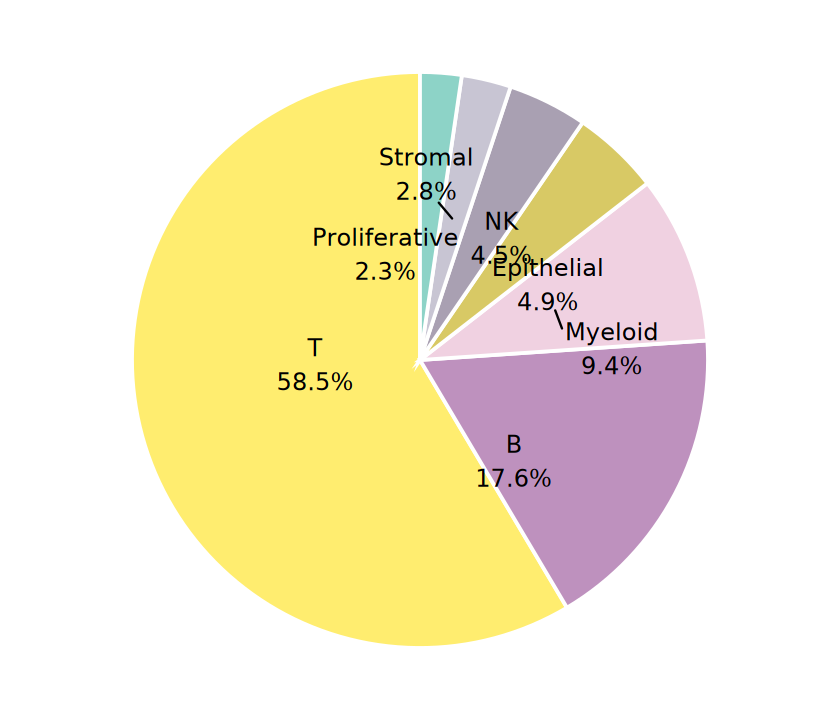

In [117]:
options(repr.plot.width = 7, repr.plot.height = 6)
cc_df |> dplyr::count(grouptype) |> 
    mutate(fraction = n / sum(n)) |>
    arrange(desc(fraction)) |>
    mutate(
        grouptype = factor(grouptype, levels = rev(grouptype)),
        label = paste0(
            grouptype, "\n", scales::percent(fraction, accuracy = 0.1)),
        ypos = cumsum(fraction) - 0.5 * fraction) |>
    ggplot(aes(x = "", y = fraction, fill = grouptype)) +
        geom_bar(
            stat = "identity", width = 1, color = "white", linewidth = 0.8) +
        geom_text_repel(
            aes(y = ypos, label = label), x = 1, size = 5) +
        coord_polar(
            theta = "y", direction = -1) +
        scale_fill_manual(
            values = colorRampPalette(brewer.pal(12, "Set3"))(
                n_distinct(cc_df$grouptype))) +
        theme_void() +
        theme(legend.position = "none")

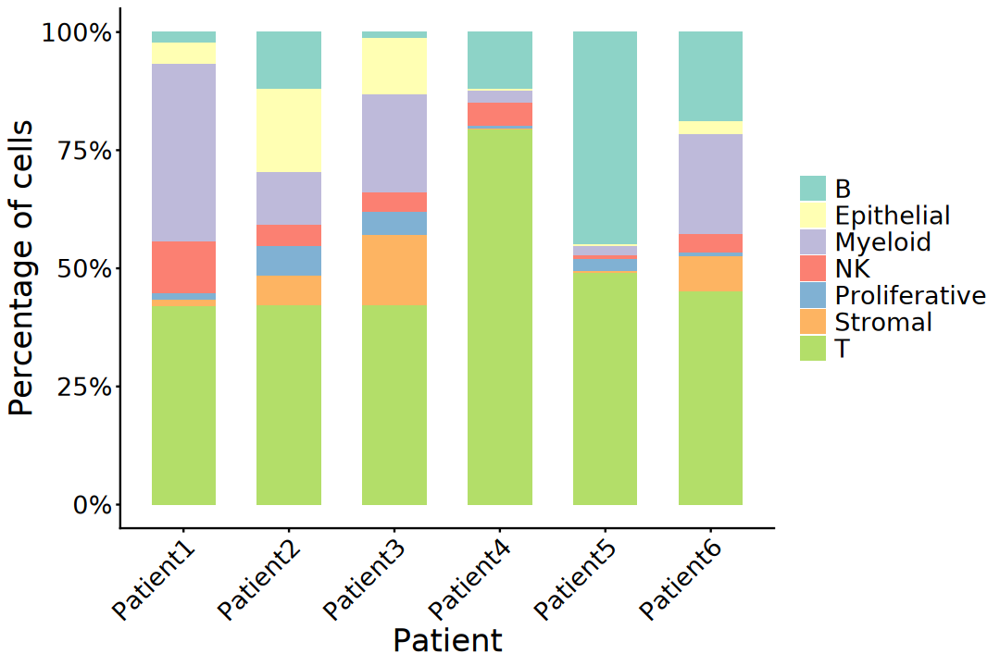

In [118]:
options(repr.plot.width = 9, repr.plot.height = 6)

cc_df |> group_by(patient) |> dplyr::count(grouptype) |>
    ggplot(aes(patient, n, fill = grouptype))+
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent) +
        labs(x = "Patient", y = "Percentage of cells") + 
        scale_fill_brewer(palette = "Set3") + 
        theme_classic()+
        theme(legend.title = element_blank(), 
              legend.text = element_text(size = 16), 
              axis.title = element_text(size = 20), 
              axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
              axis.text.y = element_text(size = 16))

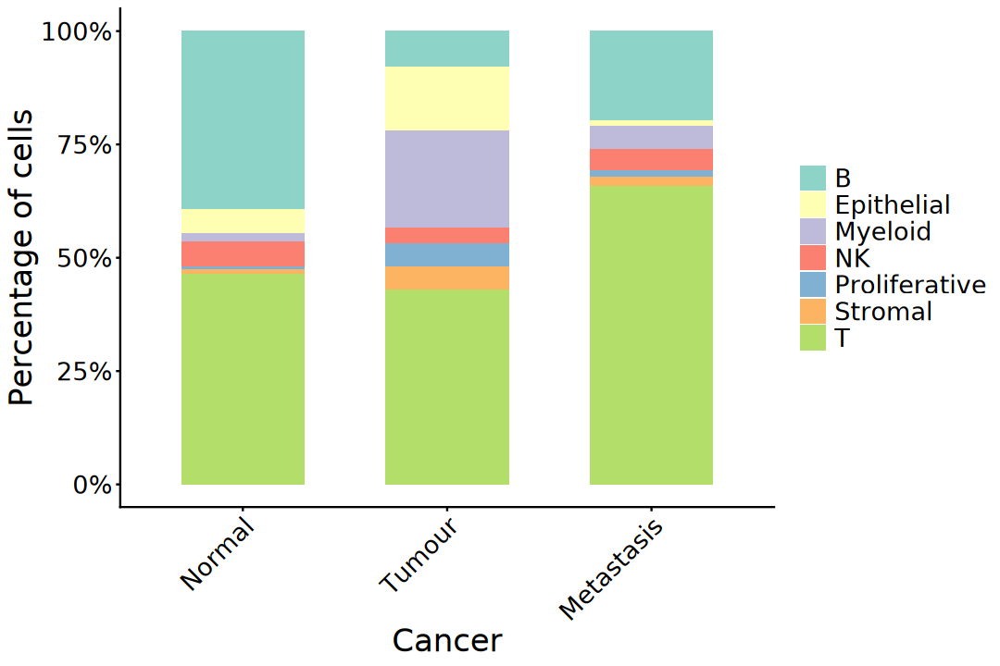

In [119]:
options(repr.plot.width = 9, repr.plot.height = 6)

cc_df |> group_by(cancer) |> dplyr::count(grouptype) |>
    ggplot(aes(cancer, n, fill = grouptype))+
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent) +
        labs(x = "Cancer", y = "Percentage of cells") + 
        scale_fill_brewer(palette = "Set3") + 
        theme_classic()+
        theme(legend.title = element_blank(), 
              legend.text = element_text(size = 16), 
              axis.title = element_text(size = 20), 
              axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
              axis.text.y = element_text(size = 16))

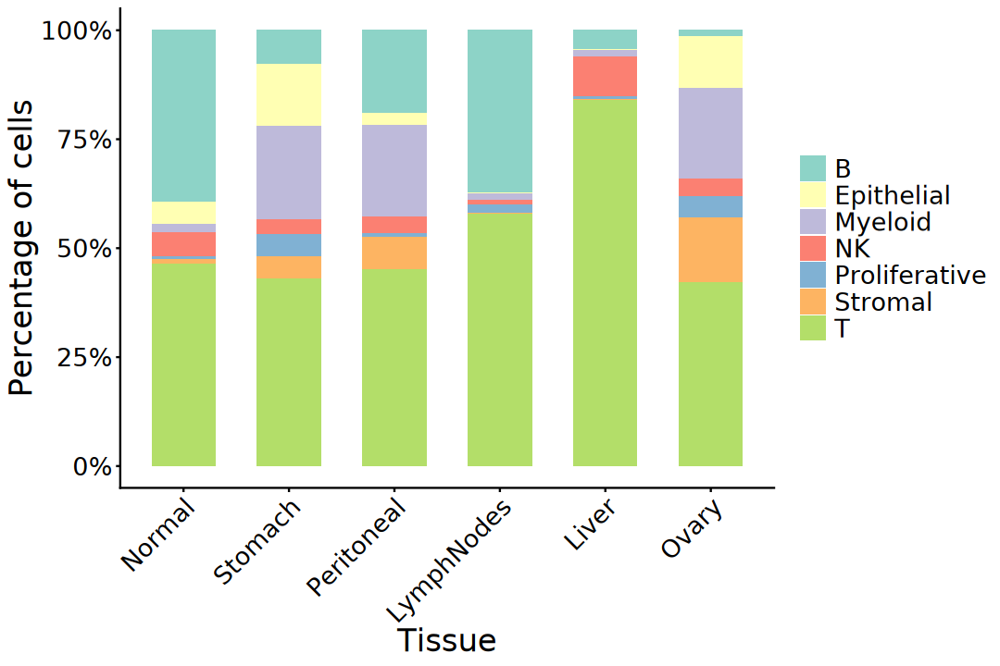

In [120]:
options(repr.plot.width = 9, repr.plot.height = 6)

cc_df |> group_by(tissue) |> dplyr::count(grouptype) |>
    ggplot(aes(tissue, n, fill = grouptype))+
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent) +
        labs(x = "Tissue", y = "Percentage of cells") + 
        scale_fill_brewer(palette = "Set3") + 
        theme_classic()+
        theme(legend.title = element_blank(), 
              legend.text = element_text(size = 16), 
              axis.title = element_text(size = 20), 
              axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
              axis.text.y = element_text(size = 16))

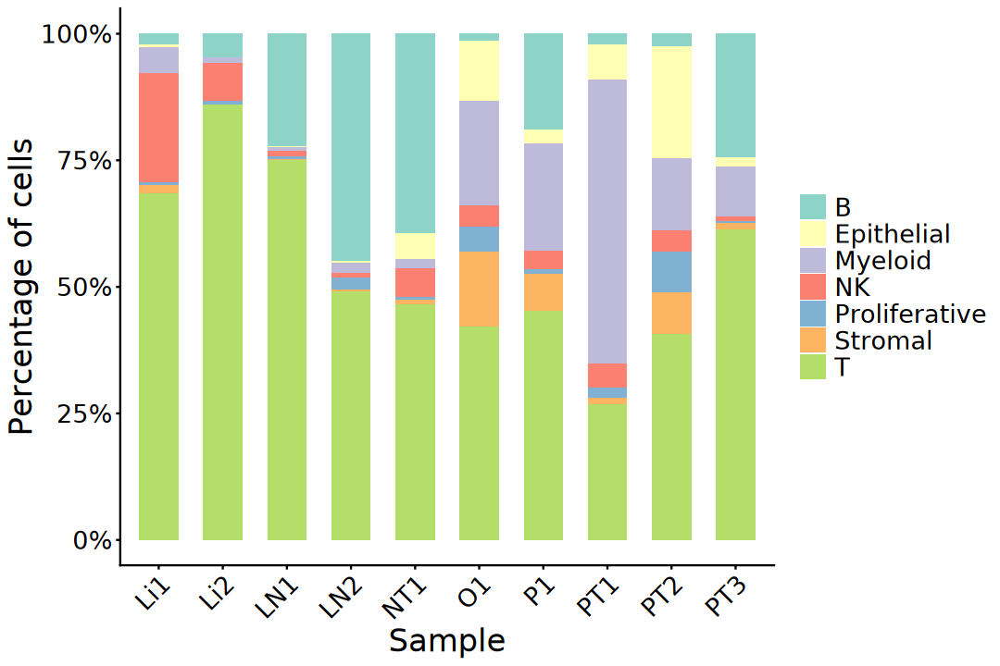

In [121]:
options(repr.plot.width = 9, repr.plot.height = 6)

cc_df |> group_by(orig.ident) |> dplyr::count(grouptype) |>
    ggplot(aes(orig.ident, n, fill = grouptype))+
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent) +
        labs(x = "Sample", y = "Percentage of cells") + 
        scale_fill_brewer(palette = "Set3") + 
        theme_classic()+
        theme(legend.title = element_blank(), 
              legend.text = element_text(size = 16), 
              axis.title = element_text(size = 20), 
              axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
              axis.text.y = element_text(size = 16))